<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/mq_hmm_kalman_duas_trilhas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# Duas trilhas até o Filtro de Kalman
## Mínimos quadrados (variáveis contínuas) e Cadeias de Markov Escondidas (variáveis discretas)

Este notebook percorre **duas linhas de raciocínio independentes** que, no final, se encontram no Filtro de Kalman.

| | **Trilha A — contínua** | **Trilha B — discreta** |
|---|---|---|
| 1 | A1. A média como mínimos quadrados (e sua forma recursiva) | B1. Probabilidades → **transição de estados** (cadeia de Markov) |
| 2 | A2. Mínimos quadrados em lote | B2. Probabilidades → **emissão de sinais** |
| 3 | A3. Ridge = *prior* gaussiano | B3. HMM: filtragem (*forward*) e suavização (*forward–backward*) |
| 4 | A4. Mínimos quadrados recursivos (RLS) | B4. Viterbi: a trajetória mais provável |
| 5 | A5. Funções de base (Função de Franke, RBF, processo gaussiano) | B5. EM (Baum–Welch): o passo M é um problema de **mínimos quadrados** |
| 6 | | B6. Máxima verossimilhança por **otimização direta** |

**Parte C — o encontro**

- C1. Kalman = algoritmo *forward* com estado contínuo
- C2. Kalman com estado parado = RLS
- C3. Suavizador RTS = mínimos quadrados em lote da trajetória inteira (o "Viterbi" do caso gaussiano)
- C4. Parâmetros: EM (Shumway–Stoffer) e otimização direta da verossimilhança
- C5. Caso não linear: EKF, **Kalman iterado = Gauss–Newton** e suavização por Gauss–Newton em lote
- C5b. Quando o EKF erra com certeza (exemplo de Bell & Cathey) e um exercício de leitura crítica (Im, 2024)
- C6. Quadro-síntese e exercícios

Duas ideias atravessam todo o notebook:

1. **Predição → atualização.** É a mesma recursão bayesiana na média recursiva, no RLS, no *forward* do HMM e no Kalman.
2. **Mínimos quadrados com momentos.** Uma única função, `mq_momentos(Sxx, Sxy)`, resolve a regressão em A2, a estimação de transições e emissões em B1/B2, o passo M do Baum–Welch em B5 e o passo M do EM do Kalman em C4. O que muda é só de onde vêm os momentos: amostrais ou **esperados**.

Textos de apoio: Welch & Bishop (*An Introduction to the Kalman Filter*), Thacker & Lacey (*The Likelihood Interpretation of the Kalman Filter*), Roweis & Ghahramani (*A Unifying Review of Linear Gaussian Models*), Stulp & Sigaud (*Many regression algorithms, one unified model*) e, para leitura crítica, Benhamou (*Kalman Filter Demystified*).

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, a, b, tol=1e-8):
    # Compara dois resultados que a teoria diz serem iguais.
    erro = np.max(np.abs(np.asarray(a, float) - np.asarray(b, float)))
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença máxima = {erro:.2e}")
    assert erro < tol, nome

def mq_momentos(Sxx, Sxy):
    # Mínimos quadrados a partir dos momentos: W = Sxx^{-1} Sxy, com ŷ = Wᵀ x.
    # Sxx = Σ x xᵀ  e  Sxy = Σ x yᵀ  (amostrais ou esperados).
    return np.linalg.solve(Sxx, Sxy)

---
# Parte A — Trilha contínua: dos mínimos quadrados ao RLS

## A1. A média é um problema de mínimos quadrados

Medimos uma constante $\theta$ com ruído: $z_k = \theta + v_k$, $v_k\sim\mathcal N(0,\sigma^2)$. O estimador de mínimos quadrados

$$\hat\theta_k=\arg\min_\theta \sum_{i=1}^{k}(z_i-\theta)^2 = \frac1k\sum_{i=1}^k z_i$$

é a média amostral. Ela pode ser calculada **sem guardar os dados**:

$$\hat\theta_k=\hat\theta_{k-1}+\underbrace{\tfrac1k}_{K_k}\,\underbrace{(z_k-\hat\theta_{k-1})}_{\text{inovação}} .$$

A variância do estimador é $P_k=\sigma^2/k$, e o ganho pode ser escrito em função dela:

$$K_k=\frac{P_{k-1}}{P_{k-1}+\sigma^2}=\frac{1/(k-1)}{1/(k-1)+1}=\frac1k,\qquad P_k=(1-K_k)P_{k-1}.$$

Essas são **exatamente as equações do Filtro de Kalman escalar** com $F=1$, $H=1$, $Q=0$ e $R=\sigma^2$. É o exemplo da "constante aleatória" de Welch & Bishop. O primeiro passo exige $P_0=\infty$, um *prior* difuso: antes do primeiro dado não sabemos nada.

OK   média recursiva = média em lote:  diferença máxima = 4.44e-16
OK   ganho K_k = 1/k:  diferença máxima = 5.55e-17
OK   variância P_k = σ²/k:  diferença máxima = 2.78e-17


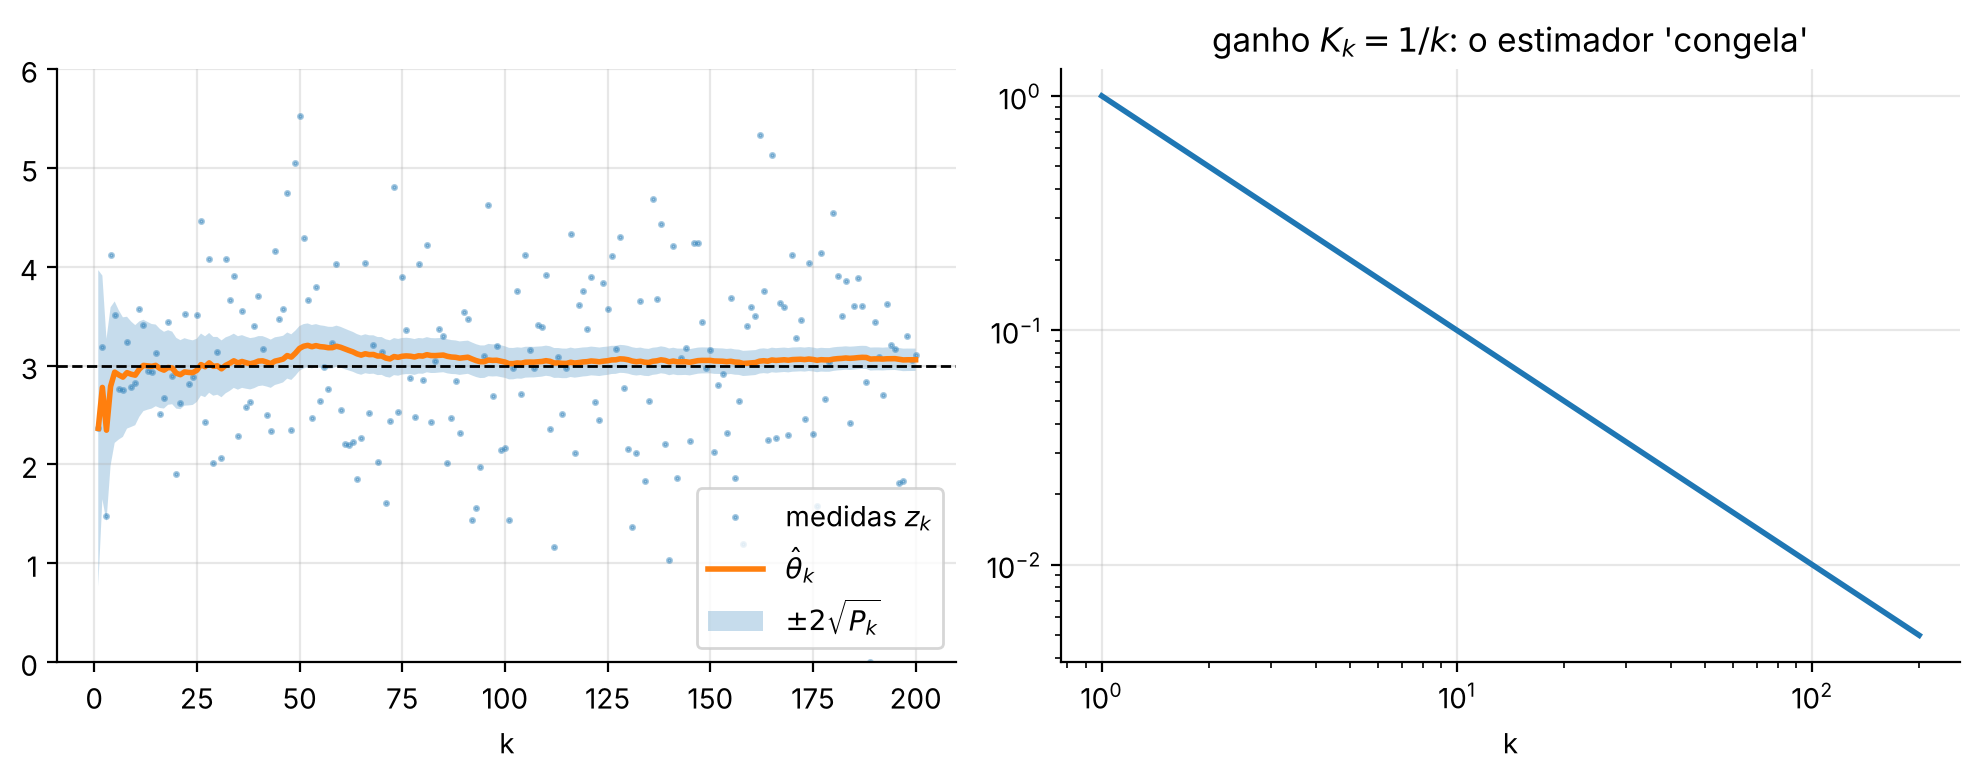

In [2]:
theta_verd, sigma, N = 3.0, 0.8, 200
z = theta_verd + sigma * rng.standard_normal(N)

theta, P = 0.0, np.inf          # prior difuso
est, Ps, Ks = [], [], []
for zk in z:
    K = 1.0 if np.isinf(P) else P / (P + sigma**2)
    theta = theta + K * (zk - theta)
    P = sigma**2 if np.isinf(P) else (1 - K) * P
    est.append(theta); Ps.append(P); Ks.append(K)
est, Ps, Ks = map(np.array, (est, Ps, Ks))

k = np.arange(1, N + 1)
confere("média recursiva = média em lote", est[-1], z.mean())
confere("ganho K_k = 1/k", Ks, 1 / k)
confere("variância P_k = σ²/k", Ps, sigma**2 / k)

fig, ax = plt.subplots(1, 2)
ax[0].plot(k, z, ".", ms=3, alpha=.4, label="medidas $z_k$")
ax[0].plot(k, est, lw=2, label=r"$\hat\theta_k$")
ax[0].fill_between(k, est - 2*np.sqrt(Ps), est + 2*np.sqrt(Ps), alpha=.25, label=r"$\pm 2\sqrt{P_k}$")
ax[0].axhline(theta_verd, color="k", ls="--", lw=1); ax[0].set_ylim(0, 6); ax[0].legend(); ax[0].set_xlabel("k")
ax[1].loglog(k, Ks, lw=2); ax[1].set_title("ganho $K_k=1/k$: o estimador 'congela'"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

**O que observar.** O ganho cai como $1/k$: cada dado novo pesa menos que o anterior. Isso é ótimo se $\theta$ for de fato constante. Se $\theta$ mudar, o estimador não acompanha. Guardar esse problema: ele vai ser resolvido pelo **fator de esquecimento** (A4) e pelo **ruído de processo** $Q$ (C1–C2).

## A2. Mínimos quadrados em lote

Generalizamos para um modelo **linear nos parâmetros**: $y = X\theta + v$, com $X\in\mathbb R^{N\times D}$. A solução satisfaz a equação normal,

$$X^\top X\,\hat\theta = X^\top y \;\;\Longrightarrow\;\; \hat\theta=(X^\top X)^{-1}X^\top y,$$

que diz que **o resíduo é ortogonal às colunas de $X$**: $X^\top(y-X\hat\theta)=0$. Geometricamente, $X\hat\theta$ é a projeção ortogonal de $y$ no espaço gerado pelas colunas.

Com ruído gaussiano, $\mathrm{Cov}(\hat\theta)=\sigma^2(X^\top X)^{-1}$. Essa é a inversa da **informação de Fisher**, e é esse $P$ que o RLS e o Kalman vão propagar.

Com $X=\mathbf 1$ (uma coluna de uns), tudo volta à média de A1. Numericamente, nunca se inverte $X^\top X$: usa-se QR ou SVD (`np.linalg.lstsq`), porque o número de condição de $X^\top X$ é o quadrado do de $X$.

In [3]:
def polinomial(x, grau):
    return np.vander(x, grau + 1, increasing=True)      # colunas 1, x, x², ...

theta_p = np.array([1.0, 2.0, -1.5])
sig_p, Np = 0.3, 40
xp = np.sort(rng.uniform(-1, 1, Np))
Xp = polinomial(xp, 2)
yp = Xp @ theta_p + sig_p * rng.standard_normal(Np)

th_normal = np.linalg.solve(Xp.T @ Xp, Xp.T @ yp)       # equação normal
th_qr = np.linalg.lstsq(Xp, yp, rcond=None)[0]          # QR/SVD
confere("equação normal = lstsq", th_normal, th_qr)
confere("resíduo ⟂ colunas de X", Xp.T @ (yp - Xp @ th_qr), np.zeros(3), tol=1e-10)

# Monte Carlo: Cov(θ̂) = σ²(XᵀX)⁻¹
amostras = np.array([np.linalg.lstsq(Xp, Xp @ theta_p + sig_p*rng.standard_normal(Np), rcond=None)[0]
                     for _ in range(20000)])
print("\nCov(θ̂) Monte Carlo:\n", np.cov(amostras.T).round(4))
print("σ²(XᵀX)⁻¹ teórica:\n", (sig_p**2 * np.linalg.inv(Xp.T @ Xp)).round(4))
print("\nnúmero de condição de X (grau 2, 12):", np.linalg.cond(Xp).round(1),
      np.linalg.cond(polinomial(xp, 12)).round(1),
      "\nnúmero de condição de XᵀX (grau 12):", f"{np.linalg.cond(polinomial(xp,12).T@polinomial(xp,12)):.1e}")

OK   equação normal = lstsq:  diferença máxima = 2.22e-16
OK   resíduo ⟂ colunas de X:  diferença máxima = 1.13e-14



Cov(θ̂) Monte Carlo:
 [[ 0.0045  0.0009 -0.0067]
 [ 0.0009  0.0069 -0.001 ]
 [-0.0067 -0.001   0.0199]]
σ²(XᵀX)⁻¹ teórica:
 [[ 0.0045  0.0009 -0.0067]
 [ 0.0009  0.0069 -0.0011]
 [-0.0067 -0.0011  0.0198]]

número de condição de X (grau 2, 12): 3.4 22183.0 
número de condição de XᵀX (grau 12): 4.9e+08


## A3. Ridge = *prior* gaussiano (o χ² de Thacker & Lacey)

Com poucos dados e muitos parâmetros, mínimos quadrados sobreajustam. Suponha que, **antes** de ver os dados, acreditamos que $\theta\sim\mathcal N(m_0,P_0)$. A posterior é gaussiana, e sua média minimiza

$$\chi^2(\theta)=(\theta-m_0)^\top P_0^{-1}(\theta-m_0)+\frac{1}{\sigma^2}\|y-X\theta\|^2 .$$

O primeiro termo é a informação a priori, e o segundo é o ajuste aos dados. Igualando o gradiente a zero:

$$\boxed{P=\Big(P_0^{-1}+\tfrac{1}{\sigma^2}X^\top X\Big)^{-1},\qquad m=P\Big(P_0^{-1}m_0+\tfrac1{\sigma^2}X^\top y\Big)}\qquad\text{(forma de informação)}$$

Com $m_0=0$ e $P_0=\delta I$, isso é a **regressão ridge** com $\lambda=\sigma^2/\delta$: *prior* largo significa pouca regularização.

Pela identidade de Woodbury, a mesma posterior pode ser escrita como uma **correção** do *prior*:

$$m=m_0+\underbrace{P_0X^\top(XP_0X^\top+\sigma^2I)^{-1}}_{K\ \text{(ganho)}}\,(y-Xm_0),\qquad P=P_0-KXP_0 .$$

Essa é a **atualização do Kalman em lote**. As duas formas são algebricamente idênticas, mas uma inverte uma matriz $D\times D$ e a outra, uma $N\times N$.

OK   forma de informação = forma de ganho (média):  diferença máxima = 1.05e-14
OK   forma de informação = forma de ganho (covariância):  diferença máxima = 3.51e-15
OK   média posterior = ridge com λ = σ²/δ:  diferença máxima = 1.07e-14


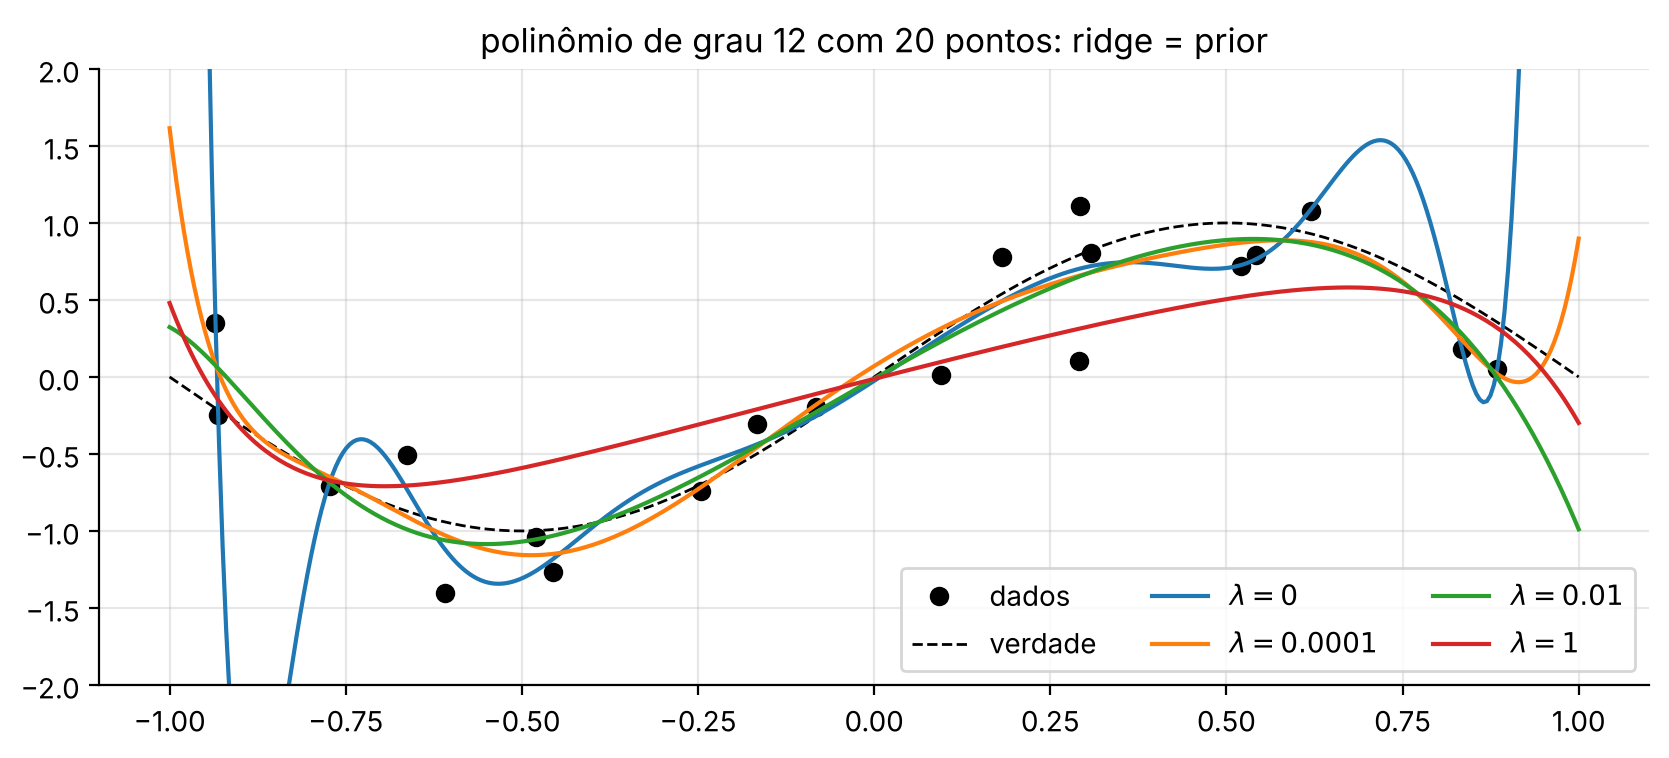

In [4]:
grau, sig_r, Nr = 12, 0.3, 20
xr = np.sort(rng.uniform(-1, 1, Nr))
yr = np.sin(np.pi * xr) + sig_r * rng.standard_normal(Nr)
Xr = polinomial(xr, grau); D = Xr.shape[1]

def posterior_informacao(X, y, s2, m0, P0):
    P = np.linalg.inv(np.linalg.inv(P0) + X.T @ X / s2)
    return P @ (np.linalg.solve(P0, m0) + X.T @ y / s2), P

def posterior_ganho(X, y, s2, m0, P0):
    K = P0 @ X.T @ np.linalg.inv(X @ P0 @ X.T + s2 * np.eye(len(y)))
    return m0 + K @ (y - X @ m0), P0 - K @ X @ P0

delta = 1.0
m0, P0 = np.zeros(D), delta * np.eye(D)
m_inf, P_inf = posterior_informacao(Xr, yr, sig_r**2, m0, P0)
m_gan, P_gan = posterior_ganho(Xr, yr, sig_r**2, m0, P0)
m_ridge = np.linalg.solve(Xr.T @ Xr + (sig_r**2 / delta) * np.eye(D), Xr.T @ yr)
confere("forma de informação = forma de ganho (média)", m_inf, m_gan)
confere("forma de informação = forma de ganho (covariância)", P_inf, P_gan)
confere("média posterior = ridge com λ = σ²/δ", m_inf, m_ridge)

xg = np.linspace(-1, 1, 400); Xg = polinomial(xg, grau)
plt.plot(xr, yr, "ko", label="dados")
plt.plot(xg, np.sin(np.pi*xg), "k--", lw=1, label="verdade")
for lam in [0.0, 1e-4, 1e-2, 1.0]:
    th = np.linalg.lstsq(np.vstack([Xr, np.sqrt(lam)*np.eye(D)]),
                         np.concatenate([yr, np.zeros(D)]), rcond=None)[0]
    plt.plot(xg, Xg @ th, label=fr"$\lambda={lam:g}$")
plt.ylim(-2, 2); plt.legend(ncol=3); plt.title(f"polinômio de grau {grau} com {Nr} pontos: ridge = prior")
plt.show()

**Truque útil (usado na célula acima e de novo em C3 e C5).** Ridge é mínimos quadrados comuns num sistema **aumentado**: basta empilhar as "pseudo-observações" do *prior* abaixo dos dados,

$$\begin{bmatrix}X\\ \sqrt\lambda\,I\end{bmatrix}\theta\approx\begin{bmatrix}y\\0\end{bmatrix}.$$

Todo *prior* gaussiano é um bloco a mais de linhas num problema de mínimos quadrados. É assim que o Kalman inteiro vai virar um único `lstsq` em C3.

## A4. Mínimos quadrados recursivos (RLS)

Quando os dados chegam um a um, aplicamos a forma de ganho de A3 com **uma linha de cada vez**. A posterior de ontem vira o *prior* de hoje. Com $x_k$ a $k$-ésima linha de $X$:

$$K_k=\frac{P_{k-1}x_k}{\sigma^2+x_k^\top P_{k-1}x_k},\qquad \hat\theta_k=\hat\theta_{k-1}+K_k\,(y_k-x_k^\top\hat\theta_{k-1}),\qquad P_k=P_{k-1}-K_kx_k^\top P_{k-1}.$$

A matriz a "inverter" é um **escalar**: é a fórmula de Sherman–Morrison. O custo é $O(D^2)$ por amostra, contra $O(D^3)$ de refazer o lote.

**Fator de esquecimento.** Para acompanhar parâmetros que mudam, infla-se $P$ antes de cada atualização, $P_{k-1}\leftarrow P_{k-1}/\lambda$ com $\lambda<1$. Isso equivale a minimizar $\sum_i\lambda^{k-i}(y_i-x_i^\top\theta)^2$ e é o mesmo que somar um ruído de processo $Q=(1/\lambda-1)P$. É o germe do Kalman.

OK   RLS (uma amostra por vez) = posterior em lote (média):  diferença máxima = 1.03e-14
OK   RLS = posterior em lote (covariância):  diferença máxima = 3.14e-15


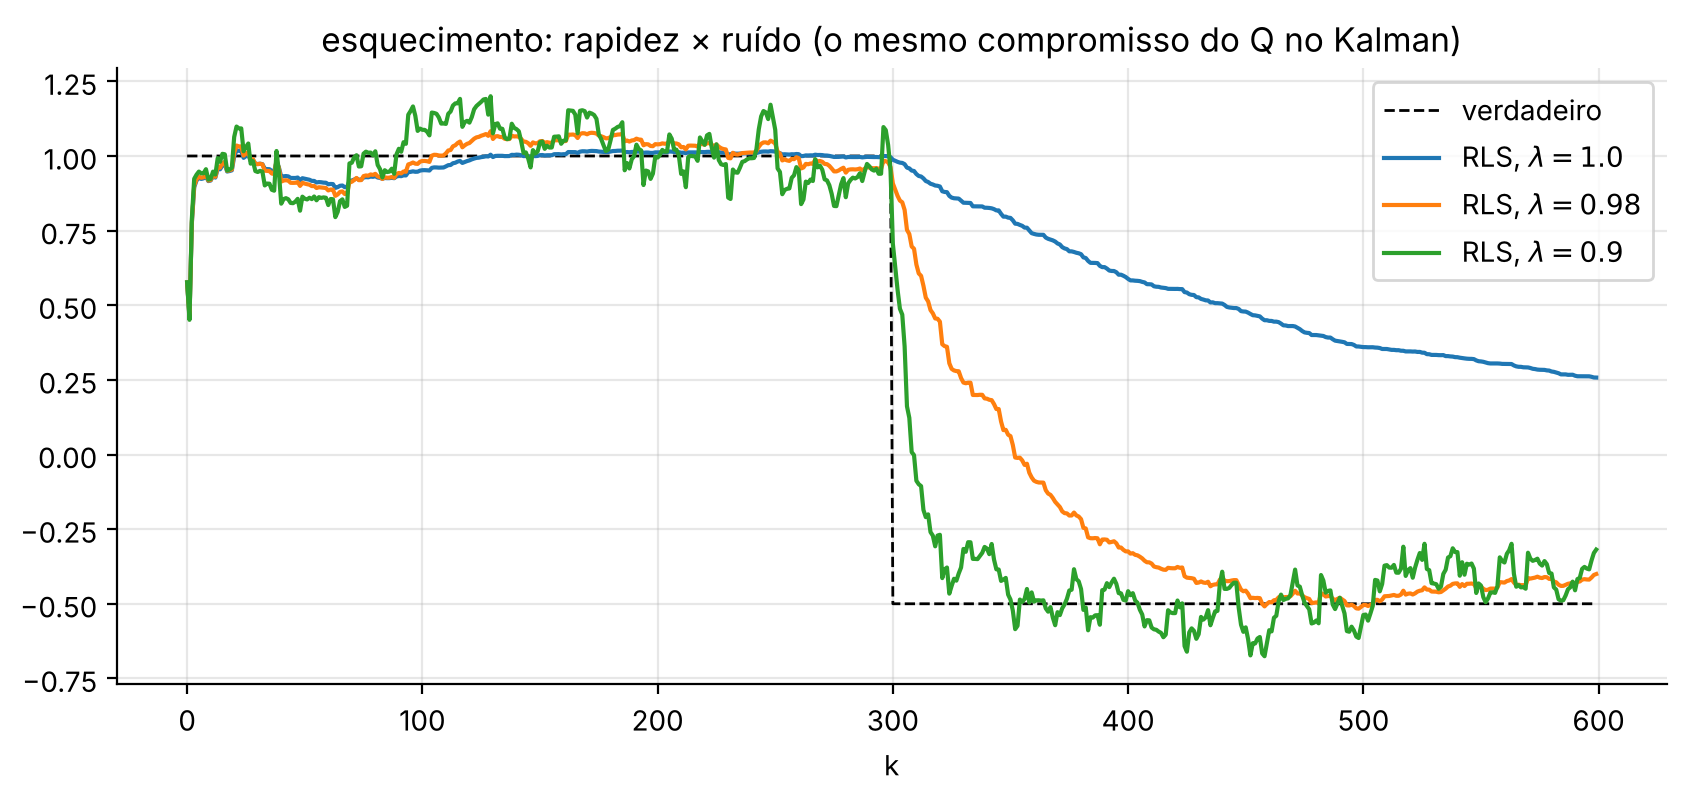

In [5]:
def rls(X, y, s2, m0, P0, lam=1.0):
    # Mínimos quadrados recursivos com fator de esquecimento lam.
    m, P = m0.astype(float).copy(), P0.astype(float).copy()
    hist = np.empty((len(y), len(m)))
    for k, (xk, yk) in enumerate(zip(X, y)):
        P = P / lam                               # esquecimento (inflação de covariância)
        Px = P @ xk
        K = Px / (s2 + xk @ Px)                   # ganho (Sherman–Morrison)
        m = m + K * (yk - xk @ m)                 # correção pela inovação
        P = P - np.outer(K, Px); P = (P + P.T) / 2
        hist[k] = m
    return m, P, hist

m_rls, P_rls, hist = rls(Xr, yr, sig_r**2, m0, P0)
confere("RLS (uma amostra por vez) = posterior em lote (média)", m_rls, m_inf, tol=1e-7)
confere("RLS = posterior em lote (covariância)", P_rls, P_inf, tol=1e-7)

# Parâmetro que muda: y_k = a_k u_k + ruído, com salto de a em k = 300
Nd = 600; u = rng.uniform(-1, 1, Nd)
a_verd = np.where(np.arange(Nd) < 300, 1.0, -0.5)
yd = a_verd * u + 0.2 * rng.standard_normal(Nd)
plt.plot(a_verd, "k--", lw=1, label="verdadeiro")
for lam in [1.0, 0.98, 0.9]:
    plt.plot(rls(u[:, None], yd, 0.04, np.zeros(1), 10*np.eye(1), lam)[2][:, 0], label=fr"RLS, $\lambda={lam}$")
plt.legend(); plt.title("esquecimento: rapidez × ruído (o mesmo compromisso do Q no Kalman)"); plt.xlabel("k"); plt.show()

**O que observar.** Com $\lambda=1$, o RLS é a média de A1 generalizada: depois de 300 amostras ele praticamente não sai do lugar. Com $\lambda=0{,}9$, a "memória efetiva" é de $1/(1-\lambda)=10$ amostras: reage rápido, mas é ruidoso. É o mesmo compromisso que Welch & Bishop mostram ao variar $R$ no exemplo da constante.

## A5. Funções de base: a Função de Franke

Até aqui $X$ continha as próprias variáveis (ou suas potências). O passo decisivo, enfatizado por Stulp & Sigaud, é que **basta o modelo ser linear nos pesos**. Escolhidas as funções de base $\phi_j$, montamos a matriz de *features* $\Phi_{ij}=\phi_j(\mathbf x_i)$ e tudo o que foi feito vale com $\Phi$ no lugar de $X$:

$$f(\mathbf x)=\sum_{j}w_j\,\phi_j(\mathbf x),\qquad \phi_j(\mathbf x)=\exp\!\Big(-\frac{\|\mathbf x-\mathbf c_j\|^2}{2s^2}\Big)\quad\text{(rede RBF com centros fixos)}.$$

Retiramos os dados de um disco em torno de $(0{,}7;\,0{,}7)$ para ver o que o *prior* faz onde não há dados.

400 pontos, 65 funções de base;  cond(Φ) = 5.7e+03


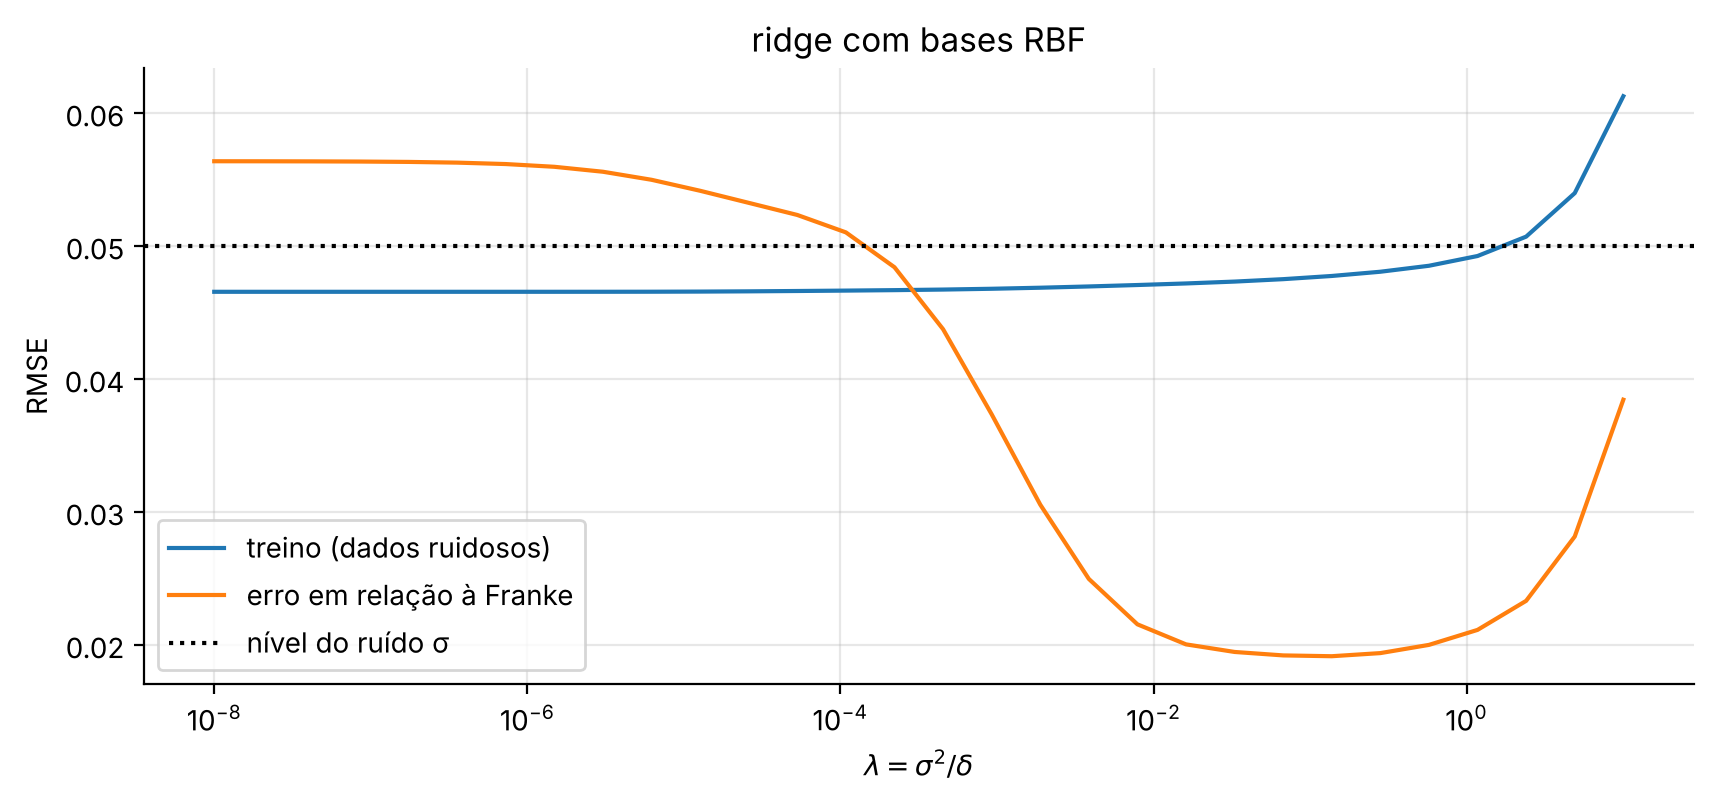

In [6]:
def franke(x, y):
    t1 = 0.75*np.exp(-((9*x - 2)**2)/4 - ((9*y - 2)**2)/4)
    t2 = 0.75*np.exp(-((9*x + 1)**2)/49 - (9*y + 1)/10)
    t3 = 0.50*np.exp(-((9*x - 7)**2)/4 - ((9*y - 3)**2)/4)
    t4 = -0.2*np.exp(-(9*x - 4)**2 - (9*y - 7)**2)
    return t1 + t2 + t3 + t4

def features_rbf(Pts, C, s):
    d2 = ((Pts[:, None, :] - C[None, :, :])**2).sum(-1)
    return np.hstack([np.ones((len(Pts), 1)), np.exp(-d2 / (2*s**2))])

# dados com um "buraco"
Pf = rng.uniform(0, 1, (900, 2))
Pf = Pf[np.hypot(Pf[:, 0] - 0.7, Pf[:, 1] - 0.7) > 0.18][:400]
sig_f = 0.05
yf = franke(*Pf.T) + sig_f * rng.standard_normal(len(Pf))

g = np.linspace(0, 1, 8); C = np.array([(a, b) for a in g for b in g])   # 8×8 centros
s_rbf = g[1] - g[0]
Phi = features_rbf(Pf, C, s_rbf)

gg = np.linspace(0, 1, 60); GX, GY = np.meshgrid(gg, gg)
Pg = np.c_[GX.ravel(), GY.ravel()]; Phig = features_rbf(Pg, C, s_rbf); fg = franke(*Pg.T)

def rmse(a, b): return np.sqrt(np.mean((a - b)**2))
print(f"{len(Pf)} pontos, {Phi.shape[1]} funções de base;  cond(Φ) = {np.linalg.cond(Phi):.1e}")
lams = np.logspace(-8, 1, 30); err_tr, err_te = [], []
for lam in lams:
    w = np.linalg.solve(Phi.T @ Phi + lam*np.eye(Phi.shape[1]), Phi.T @ yf)
    err_tr.append(rmse(Phi @ w, yf)); err_te.append(rmse(Phig @ w, fg))
plt.semilogx(lams, err_tr, label="treino (dados ruidosos)"); plt.semilogx(lams, err_te, label="erro em relação à Franke")
plt.axhline(sig_f, color="k", ls=":", label="nível do ruído σ"); plt.xlabel(r"$\lambda=\sigma^2/\delta$"); plt.ylabel("RMSE")
plt.legend(); plt.title("ridge com bases RBF"); plt.show()

Escolhido $\lambda$, calculamos os pesos **de três maneiras**: ridge em lote, RLS percorrendo os pontos um a um e **processo gaussiano**.

A terceira merece explicação. Se $w\sim\mathcal N(0,\delta I)$, então $f(\mathbf x)=\phi(\mathbf x)^\top w$ é um processo gaussiano com *kernel* $k(\mathbf x,\mathbf x')=\delta\,\phi(\mathbf x)^\top\phi(\mathbf x')$. A média preditiva do GP,

$$\bar f_*=k_*^\top(K+\sigma^2I)^{-1}y ,$$

é **a mesma** previsão do ridge. É a forma de ganho de A3, agora no "espaço das funções" ($N\times N$) em vez do "espaço dos pesos" ($D\times D$). A variância preditiva do GP é $\phi_*^\top P\,\phi_*$, onde $P$ é a matriz que o RLS propagou.

OK   RLS ponto a ponto = ridge em lote (pesos):  diferença máxima = 5.13e-12


OK   média do GP = previsão do ridge:  diferença máxima = 4.11e-12
OK   variância do GP = φᵀ P φ do RLS:  diferença máxima = 5.33e-14
RMSE em relação à Franke: 0.0366


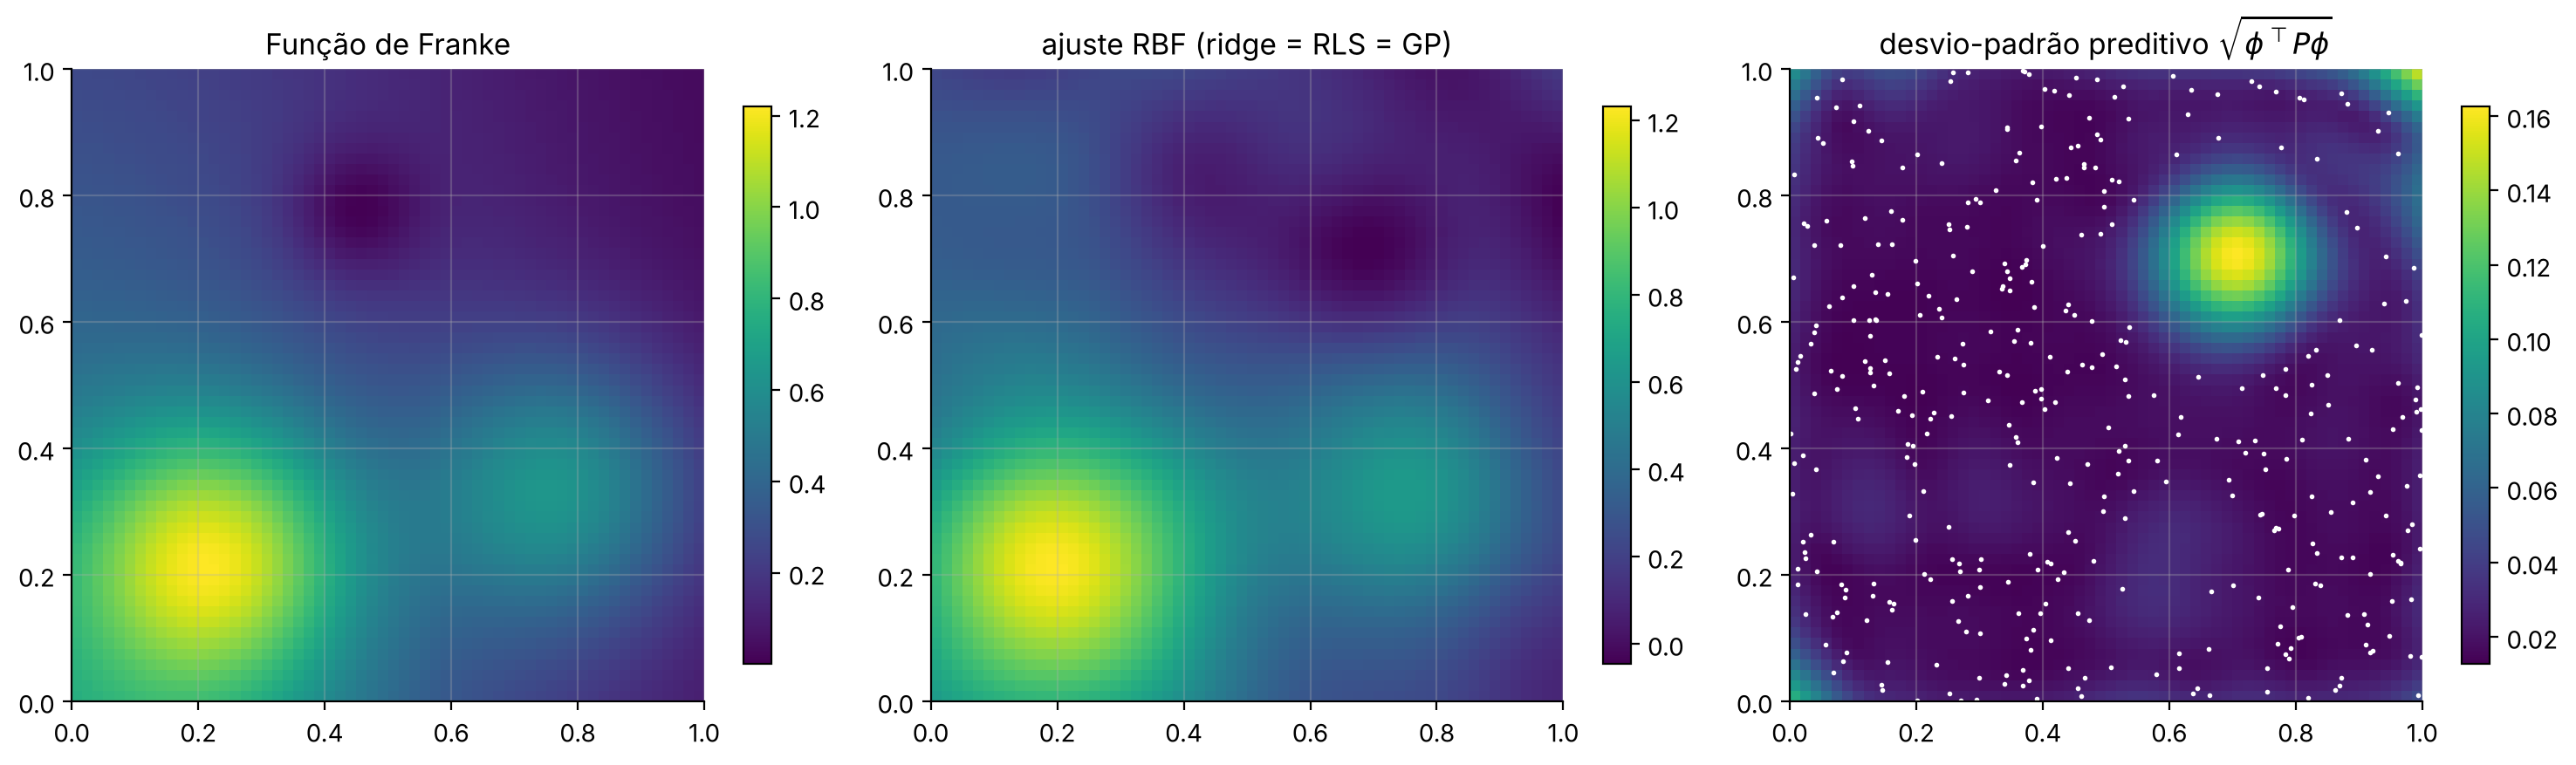

In [7]:
lam = 1e-3; delta = sig_f**2 / lam; Dm = Phi.shape[1]
w_ridge = np.linalg.solve(Phi.T @ Phi + lam*np.eye(Dm), Phi.T @ yf)
w_rls, P_w, _ = rls(Phi, yf, sig_f**2, np.zeros(Dm), delta*np.eye(Dm))
confere("RLS ponto a ponto = ridge em lote (pesos)", w_rls, w_ridge, tol=1e-6)

# Visão de processo gaussiano (espaço das funções)
K_dd = delta * Phi @ Phi.T
K_gd = delta * Phig @ Phi.T
f_gp = K_gd @ np.linalg.solve(K_dd + sig_f**2*np.eye(len(yf)), yf)
var_gp = delta*np.sum(Phig**2, 1) - np.sum(K_gd * np.linalg.solve(K_dd + sig_f**2*np.eye(len(yf)), K_gd.T).T, 1)
var_w = np.sum((Phig @ P_w) * Phig, 1)
confere("média do GP = previsão do ridge", f_gp, Phig @ w_ridge, tol=1e-6)
confere("variância do GP = φᵀ P φ do RLS", var_gp, var_w, tol=1e-7)
print(f"RMSE em relação à Franke: {rmse(Phig @ w_ridge, fg):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, Z, t in zip(ax, [fg, Phig @ w_ridge, np.sqrt(var_w)],
                   ["Função de Franke", "ajuste RBF (ridge = RLS = GP)", r"desvio-padrão preditivo $\sqrt{\phi^\top P\phi}$"]):
    im = a.imshow(Z.reshape(60, 60), origin="lower", extent=[0, 1, 0, 1], cmap="viridis"); a.set_title(t)
    plt.colorbar(im, ax=a, shrink=.8)
ax[2].plot(*Pf.T, "w.", ms=2)
plt.tight_layout(); plt.show()

**O que observar.** A incerteza cresce exatamente no buraco sem dados e nas bordas. Ali a posterior volta ao *prior*. O $P$ do RLS não é um subproduto: é o mapa de onde o modelo sabe e onde não sabe.

> **Nota crítica sobre Stulp & Sigaud.** Na eq. (58) do artigo, a solução do KRR $(\lambda I+K)^{-1}y$ aparece como se viesse da eq. (52) com $Z=K$. Na verdade, substituir $Z=K$ dá $(\lambda I+K^2)^{-1}Ky$, que penaliza $\|w\|^2$. A forma $(\lambda I+K)^{-1}y$ vem de penalizar a **norma do RKHS**, $w^\top K w$. A célula abaixo confere as duas afirmações num exemplo pequeno, com centros nos próprios dados.

In [8]:
Ps_ = rng.uniform(0, 1, (30, 2)); ys_ = franke(*Ps_.T) + 0.05*rng.standard_normal(30)
Kd = np.exp(-((Ps_[:, None] - Ps_[None])**2).sum(-1) / (2*0.3**2)); lam_k = 1e-2
a_krr = np.linalg.solve(Kd + lam_k*np.eye(30), ys_)                         # forma (58)
a_rkhs = np.linalg.solve(Kd.T @ Kd + lam_k*Kd, Kd.T @ ys_)                  # min ||y-Ka||² + λ aᵀKa
a_l2 = np.linalg.solve(Kd.T @ Kd + lam_k*np.eye(30), Kd.T @ ys_)            # min ||y-Ka||² + λ ||a||²
confere("(K+λI)⁻¹y  = penalização aᵀKa (previsões)", Kd @ a_krr, Kd @ a_rkhs, tol=1e-6)
print(f"diferença para a penalização ||a||²: {np.max(np.abs(Kd@a_krr - Kd@a_l2)):.3f}  (não é a mesma coisa)")

OK   (K+λI)⁻¹y  = penalização aᵀKa (previsões):  diferença máxima = 3.28e-12
diferença para a penalização ||a||²: 0.075  (não é a mesma coisa)


---
# Parte B — Trilha discreta: das probabilidades ao HMM

O protagonista é o **passeio do bêbado**. Há $n=7$ posições numa calçada, numeradas de 0 a 6. A cada instante o bêbado fica parado com probabilidade $p_{\text{fica}}$, ou dá um passo para a esquerda ou para a direita com probabilidades iguais. Nas pontas ele "rebate" na parede.

## B1. Probabilidades → transição de estados

A dinâmica é uma matriz estocástica $A_{ij}=P(x_t=j\mid x_{t-1}=i)$, cujas linhas somam 1. A distribuição sobre as posições evolui **linearmente**:

$$\pi_t^\top=\pi_{t-1}^\top A\qquad\Longleftrightarrow\qquad \pi_t=A^\top\pi_{t-1}.$$

Compare com $x_t=Fx_{t-1}$: o papel de $F$ é desempenhado por $A^\top$. A diferença é que aqui a linearidade está no **espaço das distribuições**, não no espaço dos estados. A distribuição estacionária é o autovetor de $A^\top$ com autovalor 1.

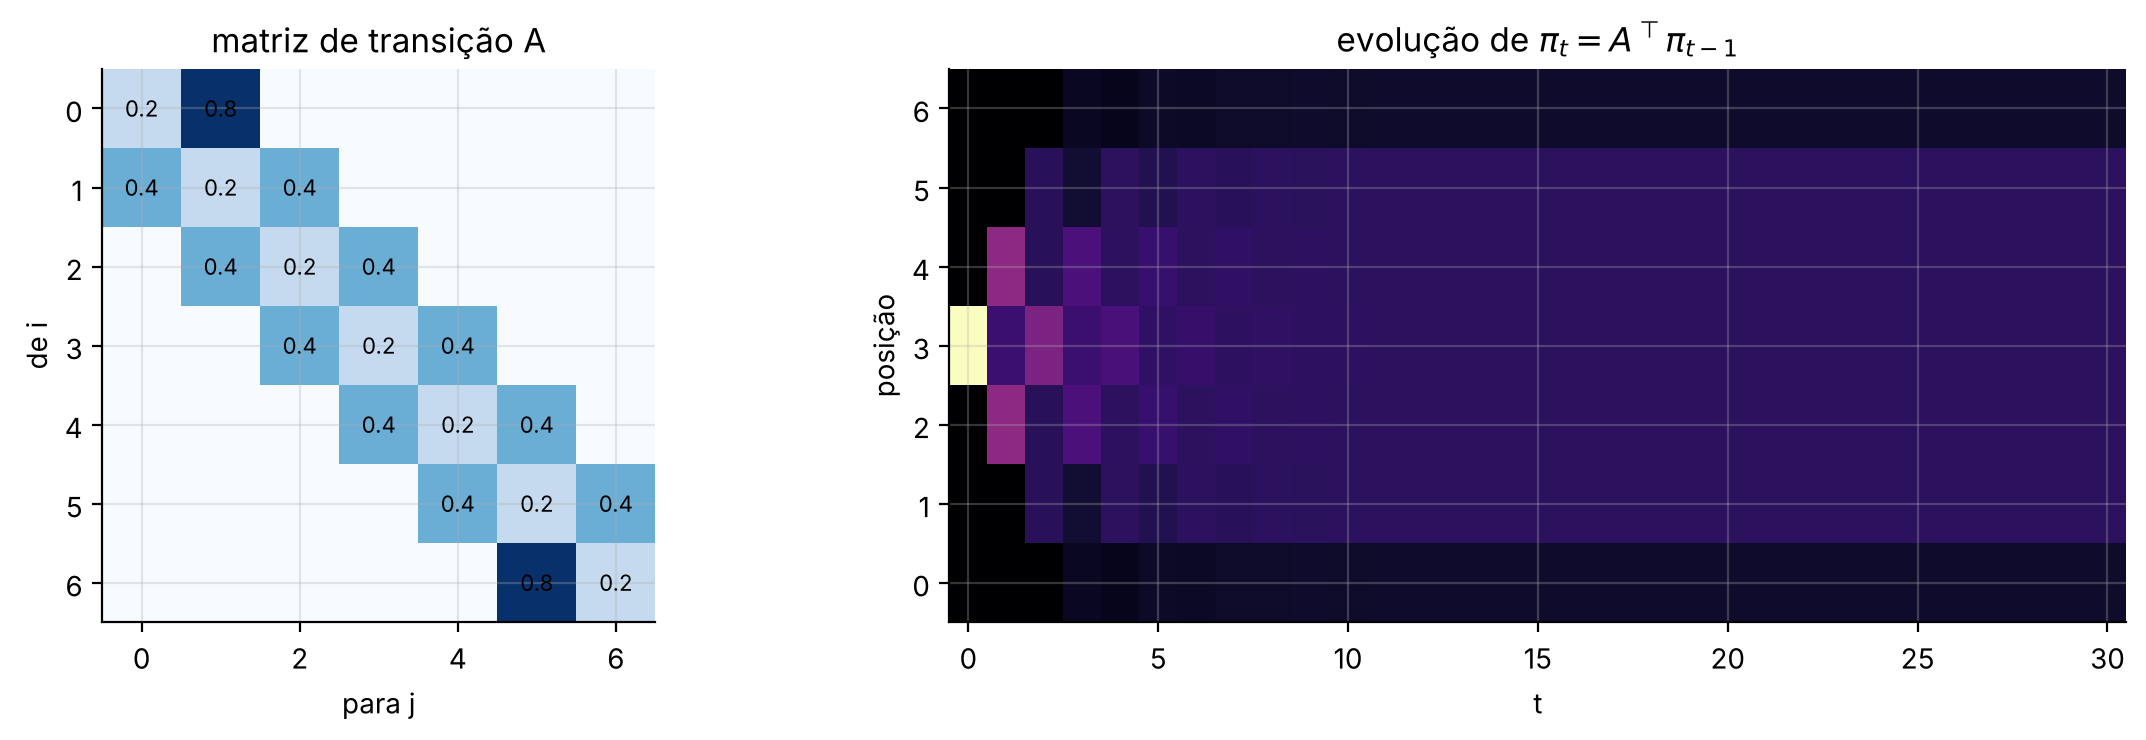

estacionária (autovetor): [0.0833 0.1667 0.1667 0.1667 0.1667 0.1667 0.0833]


In [9]:
n = 7
def matriz_vizinhos(p_centro, n=n):
    # Massa p_centro na diagonal, restante dividido entre os vizinhos (com reflexão nas pontas).
    M = np.zeros((n, n)); lado = (1 - p_centro) / 2
    for i in range(n):
        M[i, i] += p_centro
        M[i, i - 1 if i > 0 else i + 1] += lado
        M[i, i + 1 if i < n - 1 else i - 1] += lado
    return M

A_verd = matriz_vizinhos(0.2)
pis = [np.eye(n)[3]]                                  # começa com certeza na posição 3
for t in range(30): pis.append(pis[-1] @ A_verd)
w_, V_ = np.linalg.eig(A_verd.T); pi_est = np.real(V_[:, np.argmin(abs(w_ - 1))]); pi_est /= pi_est.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].imshow(A_verd, cmap="Blues"); ax[0].set_title("matriz de transição A"); ax[0].set_xlabel("para j"); ax[0].set_ylabel("de i")
for (i, j), v in np.ndenumerate(A_verd):
    if v: ax[0].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
ax[1].imshow(np.array(pis).T, aspect="auto", origin="lower", cmap="magma"); ax[1].set_title(r"evolução de $\pi_t=A^\top\pi_{t-1}$")
ax[1].set_xlabel("t"); ax[1].set_ylabel("posição"); plt.tight_layout(); plt.show()
print("estacionária (autovetor):", pi_est.round(4))

### Estimar $A$ quando os estados são observados: contagens = mínimos quadrados

Se observamos a trajetória $x_0,\dots,x_T$, a máxima verossimilhança é a frequência relativa: $\hat A_{ij}=N_{ij}/\sum_j N_{ij}$, onde $N_{ij}$ conta as transições $i\to j$.

Codifique cada estado como vetor *one-hot* $e_t$ e faça a **regressão linear** de $e_t$ sobre $e_{t-1}$, isto é, $e_t\approx A^\top e_{t-1}$:

$$\hat A=\Big(\sum_t e_{t-1}e_{t-1}^\top\Big)^{-1}\sum_t e_{t-1}e_t^\top=\mathrm{diag}(N_i)^{-1}\,N .$$

**Mínimos quadrados dão exatamente as contagens.** As linhas somam 1 automaticamente: como $X\mathbf 1=\mathbf 1$ para linhas *one-hot*, vale $(X^\top X)^{-1}X^\top\mathbf 1=\mathbf 1$. As entradas são não negativas porque $X^\top X$ é diagonal. Essa é a representação de Elliott, Aggoun & Moore: $e_t=A^\top e_{t-1}+m_t$, uma dinâmica linear com ruído não gaussiano (uma diferença de martingal).

In [10]:
def simula_cadeia(pi0, A, T, rng):
    x = np.empty(T, int); x[0] = rng.choice(len(pi0), p=pi0)
    for t in range(1, T): x[t] = rng.choice(A.shape[1], p=A[x[t - 1]])
    return x

def onehot(v, m): return np.eye(m)[v]

xs = simula_cadeia(pi_est, A_verd, 5000, rng)
E = onehot(xs, n)
A_mq = mq_momentos(E[:-1].T @ E[:-1], E[:-1].T @ E[1:])        # regressão e_t ~ e_{t-1}
Ncont = np.zeros((n, n)); np.add.at(Ncont, (xs[:-1], xs[1:]), 1)
A_cont = Ncont / Ncont.sum(1, keepdims=True)
confere("mínimos quadrados one-hot = contagens normalizadas", A_mq, A_cont, tol=1e-12)
confere("linhas de Â somam 1 sem impor restrição", A_mq.sum(1), np.ones(n), tol=1e-12)
print("erro máximo |Â - A| com 5000 passos:", np.abs(A_mq - A_verd).max().round(3))

OK   mínimos quadrados one-hot = contagens normalizadas:  diferença máxima = 1.11e-16
OK   linhas de Â somam 1 sem impor restrição:  diferença máxima = 1.11e-16
erro máximo |Â - A| com 5000 passos: 0.043


## B2. Probabilidades → emissão de sinais

O bêbado não é visto diretamente. Cada posição tem uma placa com uma letra (A, B, …, G), e um sensor lê a letra da posição atual com probabilidade $p_{\text{certo}}$. Com o restante da probabilidade, lê a letra de um vizinho. A emissão é outra matriz estocástica: $B_{ik}=P(y_t=k\mid x_t=i)$.

Uma única leitura já permite a **atualização bayesiana**:

$$P(x\mid y)\propto \underbrace{P(y\mid x)}_{\text{verossimilhança}}\;\underbrace{P(x)}_{\text{prior}} .$$

Esse é o passo de "correção" que, em A3, era a passagem do *prior* $\mathcal N(m_0,P_0)$ para a posterior. Com estados observados, $B$ também se estima por mínimos quadrados *one-hot* (letra sobre posição).

erro máximo |B̂ - B| (estados observados, 5000 leituras): 0.053


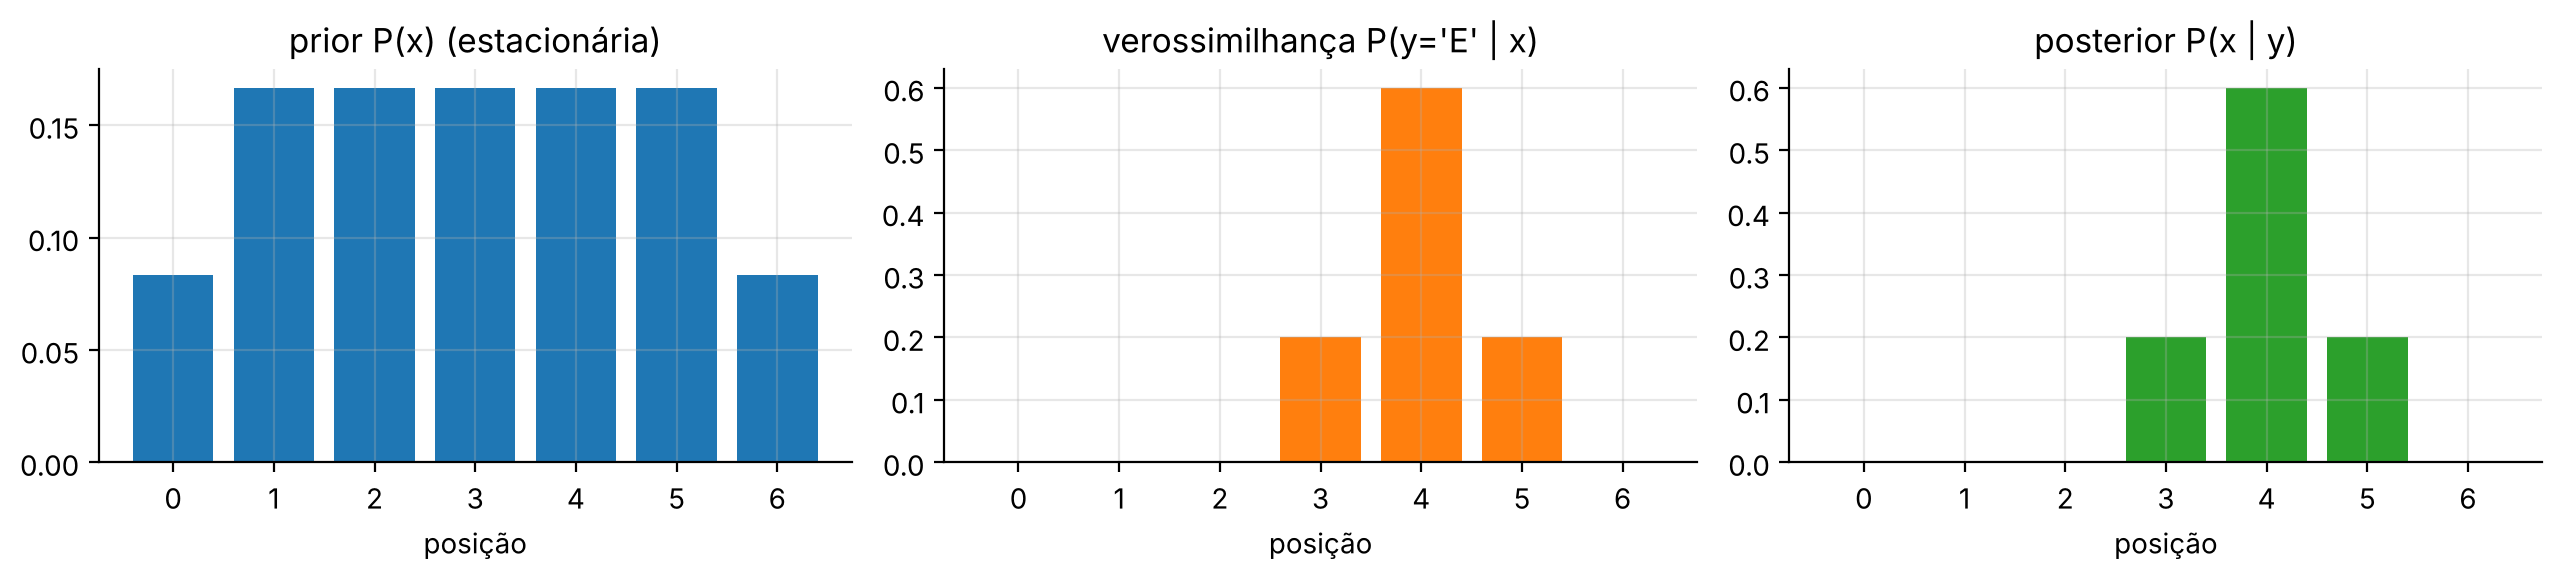

In [11]:
letras = np.array(list("ABCDEFG"))
B_verd = matriz_vizinhos(0.6)
def simula_hmm(pi0, A, B, T, rng):
    x = simula_cadeia(pi0, A, T, rng)
    y = np.array([rng.choice(B.shape[1], p=B[xi]) for xi in x])
    return x, y

ys = np.array([rng.choice(n, p=B_verd[xi]) for xi in xs])
Y1 = onehot(ys, n)
B_mq = mq_momentos(E.T @ E, E.T @ Y1)
print("erro máximo |B̂ - B| (estados observados, 5000 leituras):", np.abs(B_mq - B_verd).max().round(3))

k_lida = 4   # leu-se a letra "E"
post = B_verd[:, k_lida] * pi_est; post /= post.sum()
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].bar(range(n), pi_est); ax[0].set_title("prior P(x) (estacionária)")
ax[1].bar(range(n), B_verd[:, k_lida], color="C1"); ax[1].set_title(f"verossimilhança P(y='{letras[k_lida]}' | x)")
ax[2].bar(range(n), post, color="C2"); ax[2].set_title("posterior P(x | y)")
for a in ax: a.set_xticks(range(n)); a.set_xlabel("posição")
plt.tight_layout(); plt.show()

## B3. HMM: filtragem (*forward*) e suavização (*forward–backward*)

Juntando transição e emissão temos o HMM. A filtragem $\alpha_t(i)=P(x_t=i\mid y_{0:t})$ alterna as duas operações das seções anteriores:

$$\underbrace{\alpha_t^-=\alpha_{t-1}A}_{\text{predição (B1)}}\qquad\qquad \underbrace{\alpha_t=\frac{\alpha_t^-\odot B_{:,y_t}}{c_t}}_{\text{atualização (B2)}},\qquad c_t=P(y_t\mid y_{0:t-1}).$$

A verossimilhança sai de graça, como produto das constantes de normalização: $\log P(y_{0:T})=\sum_t\log c_t$. No Kalman, $c_t$ será a densidade da **inovação** (C1).

A recursão *backward* $\beta_t$ incorpora as observações futuras e dá as marginais suavizadas $\gamma_t=P(x_t\mid y_{0:T})$ e as conjuntas $\xi_t(i,j)=P(x_t=i,x_{t+1}=j\mid y_{0:T})$. Estas são as "contagens esperadas" que o EM vai usar.

OK   log P(y) do forward = soma sobre 117 649 caminhos:  diferença máxima = 0.00e+00
OK   γ_t do forward–backward = marginais por força bruta:  diferença máxima = 4.44e-16

acerto do argmax: leitura crua 0.606 | filtrado 0.656 | suavizado 0.716


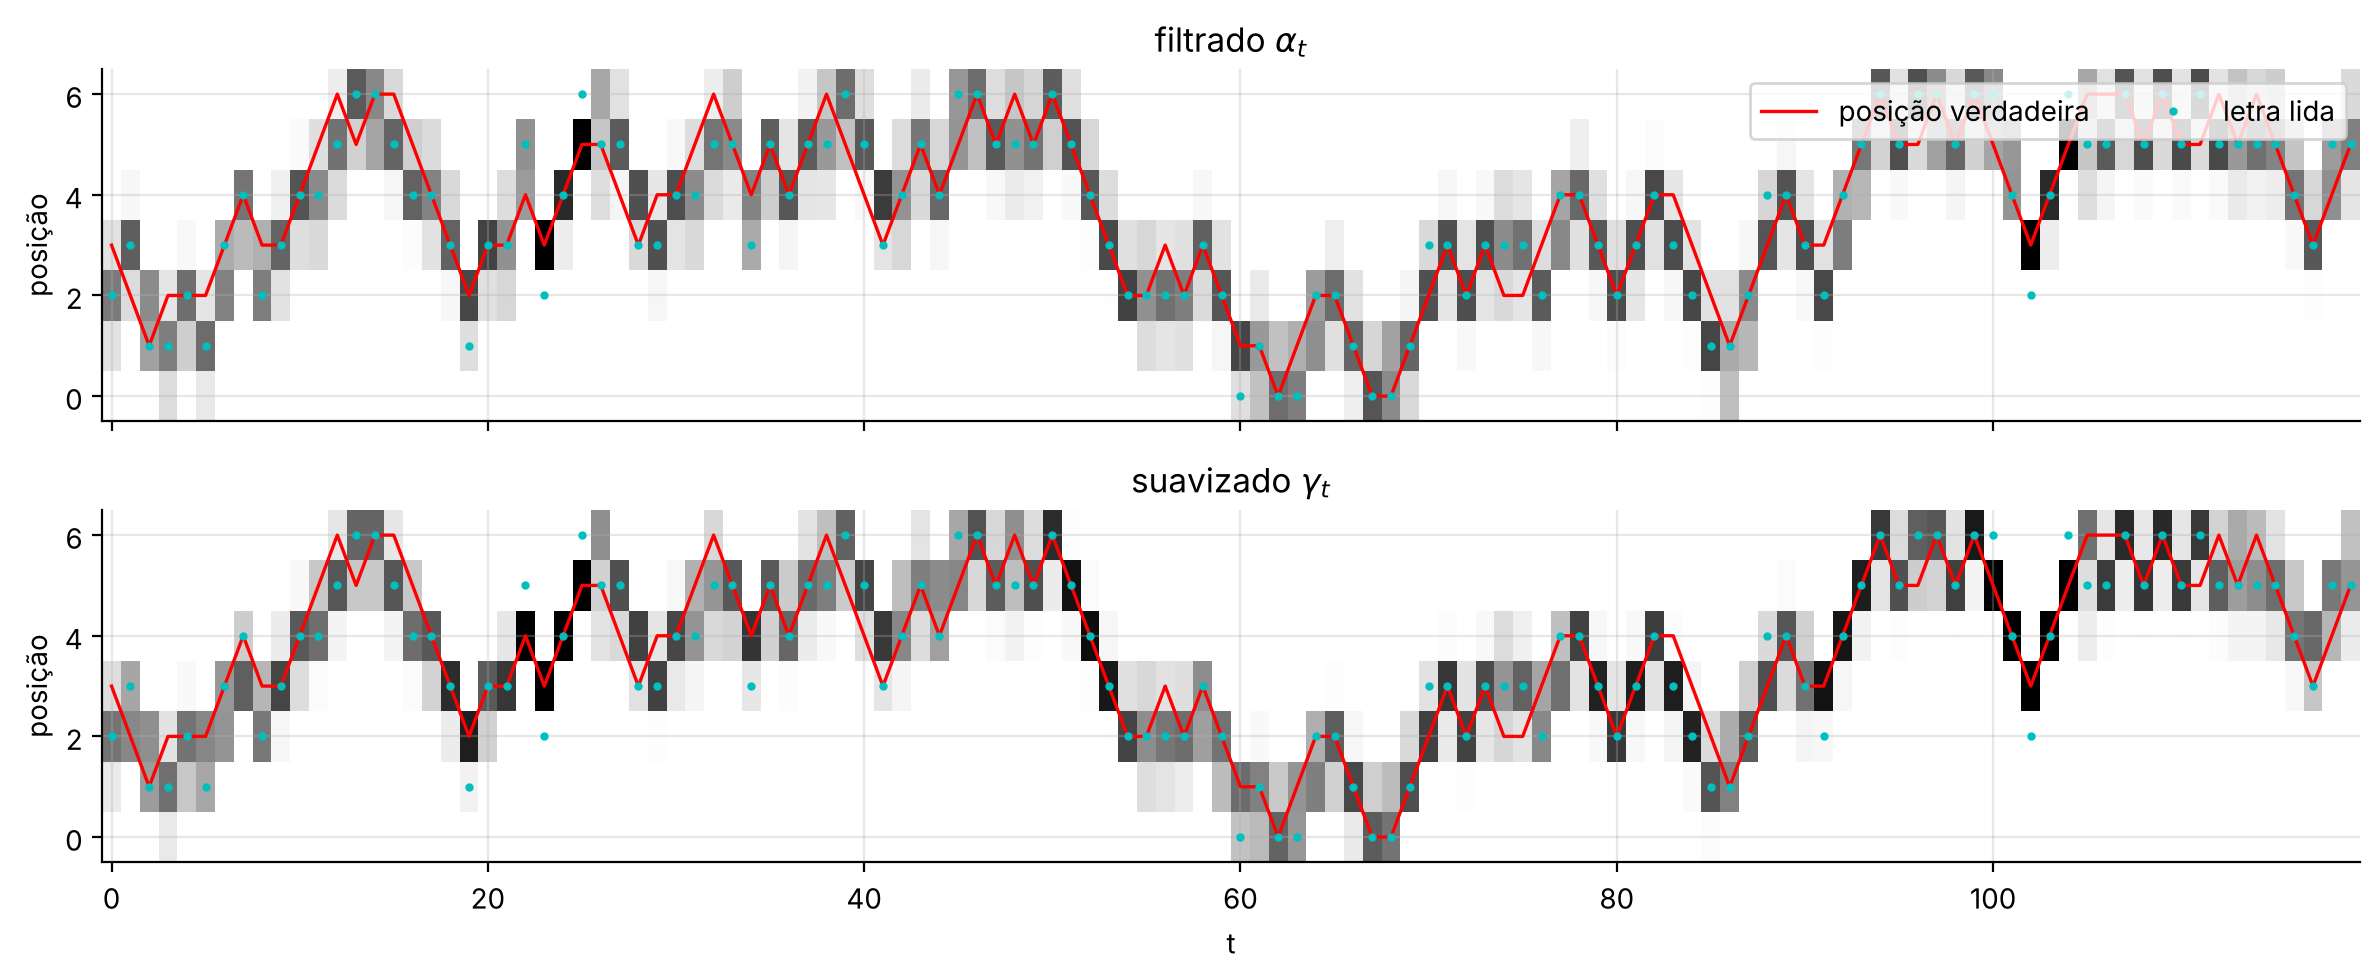

In [12]:
def forward(pi0, A, B, y):
    T, N = len(y), len(pi0)
    alpha, c = np.empty((T, N)), np.empty(T)
    a_pred = pi0
    for t in range(T):
        if t > 0: a_pred = alpha[t - 1] @ A          # predição
        u = a_pred * B[:, y[t]]                       # atualização
        c[t] = u.sum(); alpha[t] = u / c[t]
    return alpha, c, np.log(c).sum()

def backward(A, B, y, c):
    T, N = len(y), A.shape[0]
    beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = A @ (B[:, y[t + 1]] * beta[t + 1]) / c[t + 1]
    return beta

def e_passo_hmm(pi0, A, B, y):
    alpha, c, ll = forward(pi0, A, B, y)
    beta = backward(A, B, y, c)
    gamma = alpha * beta
    Xi = np.einsum("ti,ij,tj->ij", alpha[:-1], A, (B[:, y[1:]].T * beta[1:]) / c[1:, None])
    return gamma, Xi, ll, alpha

# conferência por força bruta numa sequência curta: soma sobre os 7^6 caminhos
xc, yc = simula_hmm(pi_est, A_verd, B_verd, 6, rng)
cam = np.array(list(itertools.product(range(n), repeat=6)))
p_cam = pi_est[cam[:, 0]] * B_verd[cam[:, 0], yc[0]]
for t in range(1, 6): p_cam *= A_verd[cam[:, t - 1], cam[:, t]] * B_verd[cam[:, t], yc[t]]
confere("log P(y) do forward = soma sobre 117 649 caminhos", forward(pi_est, A_verd, B_verd, yc)[2], np.log(p_cam.sum()), tol=1e-10)
gam_bf = np.array([[p_cam[cam[:, t] == i].sum() for i in range(n)] for t in range(6)]) / p_cam.sum()
confere("γ_t do forward–backward = marginais por força bruta", e_passo_hmm(pi_est, A_verd, B_verd, yc)[0], gam_bf, tol=1e-12)

# uma sequência longa para o resto da Parte B
T_h = 3000
x_h, y_h = simula_hmm(pi_est, A_verd, B_verd, T_h, rng)
gamma, Xi, ll_verd, alpha = e_passo_hmm(pi_est, A_verd, B_verd, y_h)
print(f"\nacerto do argmax: leitura crua {np.mean(y_h == x_h):.3f} | filtrado {np.mean(alpha.argmax(1) == x_h):.3f}"
      f" | suavizado {np.mean(gamma.argmax(1) == x_h):.3f}")

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for a, M, t in zip(ax, [alpha, gamma], [r"filtrado $\alpha_t$", r"suavizado $\gamma_t$"]):
    a.imshow(M[:120].T, aspect="auto", origin="lower", cmap="Greys")
    a.plot(x_h[:120], "r-", lw=1.2, label="posição verdadeira"); a.plot(y_h[:120], "c.", ms=4, label="letra lida")
    a.set_ylabel("posição"); a.set_title(t)
ax[0].legend(loc="upper right", ncol=2); ax[1].set_xlabel("t"); plt.tight_layout(); plt.show()

## B4. Viterbi: a trajetória mais provável

$\arg\max_i\gamma_t(i)$ escolhe o melhor estado **em cada instante**, mas a sequência desses melhores estados não precisa ser a melhor **sequência**. Ela pode até ser impossível, por exemplo um salto de duas posições, que tem probabilidade zero em $A$. O algoritmo de Viterbi troca a soma do *forward* por um máximo (programação dinâmica, *max-product*):

$$\delta_t(j)=\max_i\big[\delta_{t-1}(i)+\log A_{ij}\big]+\log B_{j,y_t}.$$

Como observam Roweis & Ghahramani, no caso **gaussiano** essa distinção desaparece: a posterior é unimodal, e a sequência das médias suavizadas *é* a trajetória MAP. Em C3 veremos que essa trajetória é a solução de **um** problema de mínimos quadrados.

In [13]:
def viterbi(pi0, A, B, y):
    with np.errstate(divide="ignore"):
        lA, lB, lp = np.log(A), np.log(B), np.log(pi0)
    T, N = len(y), len(pi0)
    psi = np.zeros((T, N), int); d = lp + lB[:, y[0]]
    for t in range(1, T):
        s = d[:, None] + lA
        psi[t] = s.argmax(0); d = s.max(0) + lB[:, y[t]]
    x = np.empty(T, int); x[-1] = d.argmax()
    for t in range(T - 1, 0, -1): x[t - 1] = psi[t, x[t]]
    return x

confere("Viterbi = argmax por força bruta (T = 6)", viterbi(pi_est, A_verd, B_verd, yc), cam[p_cam.argmax()], tol=0.5)
x_vit = viterbi(pi_est, A_verd, B_verd, y_h); x_marg = gamma.argmax(1)
def n_impossiveis(x): return int(np.sum(A_verd[x[:-1], x[1:]] == 0))
print(f"acerto por instante:  Viterbi {np.mean(x_vit == x_h):.3f} | argmax das marginais {np.mean(x_marg == x_h):.3f}")
print(f"transições impossíveis: Viterbi {n_impossiveis(x_vit)} | argmax das marginais {n_impossiveis(x_marg)}")

def log_conjunta(x, y, pi0, A, B):
    with np.errstate(divide="ignore"):
        return np.log(pi0[x[0]]) + np.log(A[x[:-1], x[1:]]).sum() + np.log(B[x, y]).sum()
print(f"log p(x, y) da trajetória:  Viterbi {log_conjunta(x_vit, y_h, pi_est, A_verd, B_verd):.1f}"
      f" | argmax das marginais {log_conjunta(x_marg, y_h, pi_est, A_verd, B_verd):.1f}")

OK   Viterbi = argmax por força bruta (T = 6):  diferença máxima = 0.00e+00
acerto por instante:  Viterbi 0.693 | argmax das marginais 0.716
transições impossíveis: Viterbi 0 | argmax das marginais 0
log p(x, y) da trajetória:  Viterbi -4940.8 | argmax das marginais -5288.4


**O que observar.** O argmax das marginais acerta **um pouco mais por instante**, porque é isso que ele otimiza. O Viterbi tem a maior probabilidade **conjunta** e nunca viola a dinâmica. Nesta simulação o argmax das marginais não chegou a violar a dinâmica, mas nada o impede: o exercício 5 pede um exemplo em que ele produz um salto que $A$ proíbe. A escolha entre os dois depende da pergunta: "onde ele estava em cada instante?" ou "que caminho ele fez?".

## B5. EM (Baum–Welch): o passo M é um problema de mínimos quadrados

Agora **nem $A$ nem $B$ são conhecidos**, e os estados não são observados. Em B1 e B2 estimamos $A$ e $B$ por mínimos quadrados *one-hot* porque víamos $e_t$. O EM faz o óbvio: troca os momentos amostrais pelos **momentos esperados** sob a posterior,

$$e_{t-1}e_{t-1}^\top\;\to\;\mathbb E[e_{t-1}e_{t-1}^\top]=\mathrm{diag}(\gamma_{t-1}),\qquad e_{t-1}e_t^\top\;\to\;\mathbb E[e_{t-1}e_t^\top]=\xi_{t-1},$$

e resolve **o mesmo problema de mínimos quadrados**:

$$\hat A=\Big(\sum_t\mathrm{diag}(\gamma_{t-1})\Big)^{-1}\sum_t\xi_{t-1},\qquad \hat B=\Big(\sum_t\mathrm{diag}(\gamma_t)\Big)^{-1}\sum_t\gamma_t\,\mathrm{onehot}(y_t)^\top .$$

São as fórmulas clássicas de Baum–Welch ("contagens esperadas normalizadas"), escritas com a mesma `mq_momentos`. Em C4, o passo M do EM do Kalman será **literalmente a mesma linha de código**, com as médias e covariâncias do suavizador RTS no lugar de $\gamma$ e $\xi$.

A inicialização de $B$ com diagonal dominante quebra a simetria de permutação dos rótulos dos estados: a placa A fica "perto" da posição 0, e assim por diante. Sem isso, o EM pode encontrar a solução com os estados renumerados.

log-verossimilhança: inicial -6012.1 → final -4241.7  (com os parâmetros verdadeiros: -4251.5)
EM monótono: OK


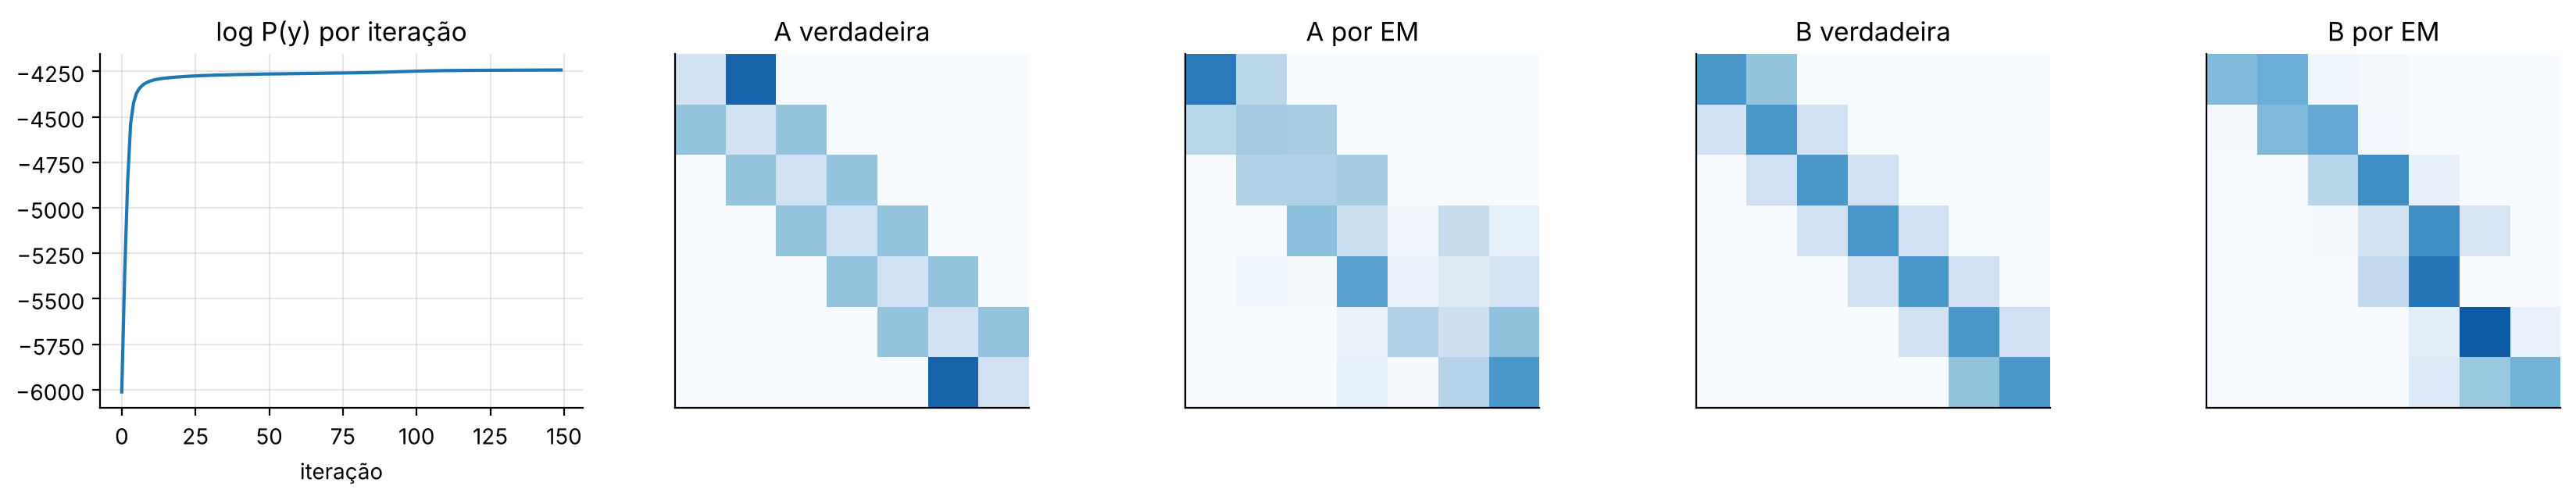

In [14]:
def baum_welch(y, A, B, pi0, n_iter=150):
    lls = []
    for _ in range(n_iter):
        gamma, Xi, ll, _ = e_passo_hmm(pi0, A, B, y)               # passo E
        lls.append(ll)
        A = mq_momentos(np.diag(gamma[:-1].sum(0)), Xi)            # passo M = MQ com momentos esperados
        B = mq_momentos(np.diag(gamma.sum(0)), gamma.T @ onehot(y, B.shape[1]))
        pi0 = gamma[0]
    return A, B, pi0, np.array(lls)

A_ini = rng.dirichlet(np.ones(n), n)
B_ini = 0.5*np.eye(n) + 0.5*rng.dirichlet(np.ones(n), n)
pi_ini = np.ones(n) / n
A_em, B_em, pi_em, lls_em = baum_welch(y_h, A_ini, B_ini, pi_ini)

assert np.all(np.diff(lls_em) > -1e-8), "EM deveria ser monótono"
print(f"log-verossimilhança: inicial {lls_em[0]:.1f} → final {lls_em[-1]:.1f}  (com os parâmetros verdadeiros: {ll_verd:.1f})")
print("EM monótono: OK")
fig, ax = plt.subplots(1, 5, figsize=(17, 3.3))
ax[0].plot(lls_em); ax[0].set_title("log P(y) por iteração"); ax[0].set_xlabel("iteração")
for a, M, t in zip(ax[1:], [A_verd, A_em, B_verd, B_em], ["A verdadeira", "A por EM", "B verdadeira", "B por EM"]):
    a.imshow(M, cmap="Blues", vmin=0, vmax=1); a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

O EM chega a uma log-verossimilhança **maior** que a dos parâmetros verdadeiros. Isso não é erro: o estimador de máxima verossimilhança ajusta-se à amostra, e com $2\times 42$ parâmetros livres sobra espaço para isso.

## B6. Máxima verossimilhança por otimização direta

O EM não é a única via. A log-verossimilhança $\ell(\theta)=\sum_t\log c_t$ é uma função diferenciável dos parâmetros e pode ser entregue a um otimizador. Para manter as restrições (linhas positivas que somam 1), parametrizamos cada linha por *softmax*: $A_{ij}=e^{a_{ij}}/\sum_k e^{a_{ik}}$.

O gradiente não precisa de diferenciação automática. Pela **identidade de Fisher**, o gradiente da verossimilhança marginal é o valor esperado do gradiente da verossimilhança completa, e as mesmas contagens esperadas do passo E fornecem

$$\frac{\partial\ell}{\partial a_{ij}}=\Xi_{ij}-A_{ij}\sum_k\Xi_{ik},\qquad \Xi=\sum_t\xi_t .$$

No seu notebook de HMM esse gradiente foi obtido por JAX; aqui ele sai do *forward–backward*. Conferimos primeiro o gradiente analítico contra diferenças finitas e depois otimizamos com L-BFGS a partir do mesmo ponto inicial do EM.

OK   gradiente pela identidade de Fisher = diferenças finitas:  diferença máxima = 1.25e-08


log-verossimilhança final:  EM -4241.72  |  L-BFGS -4259.17  (411 iterações)
30 iterações de EM a partir do ponto do L-BFGS: -4259.17 → -4259.16  
probabilidades < 10⁻³ na solução do EM: 42 de 98


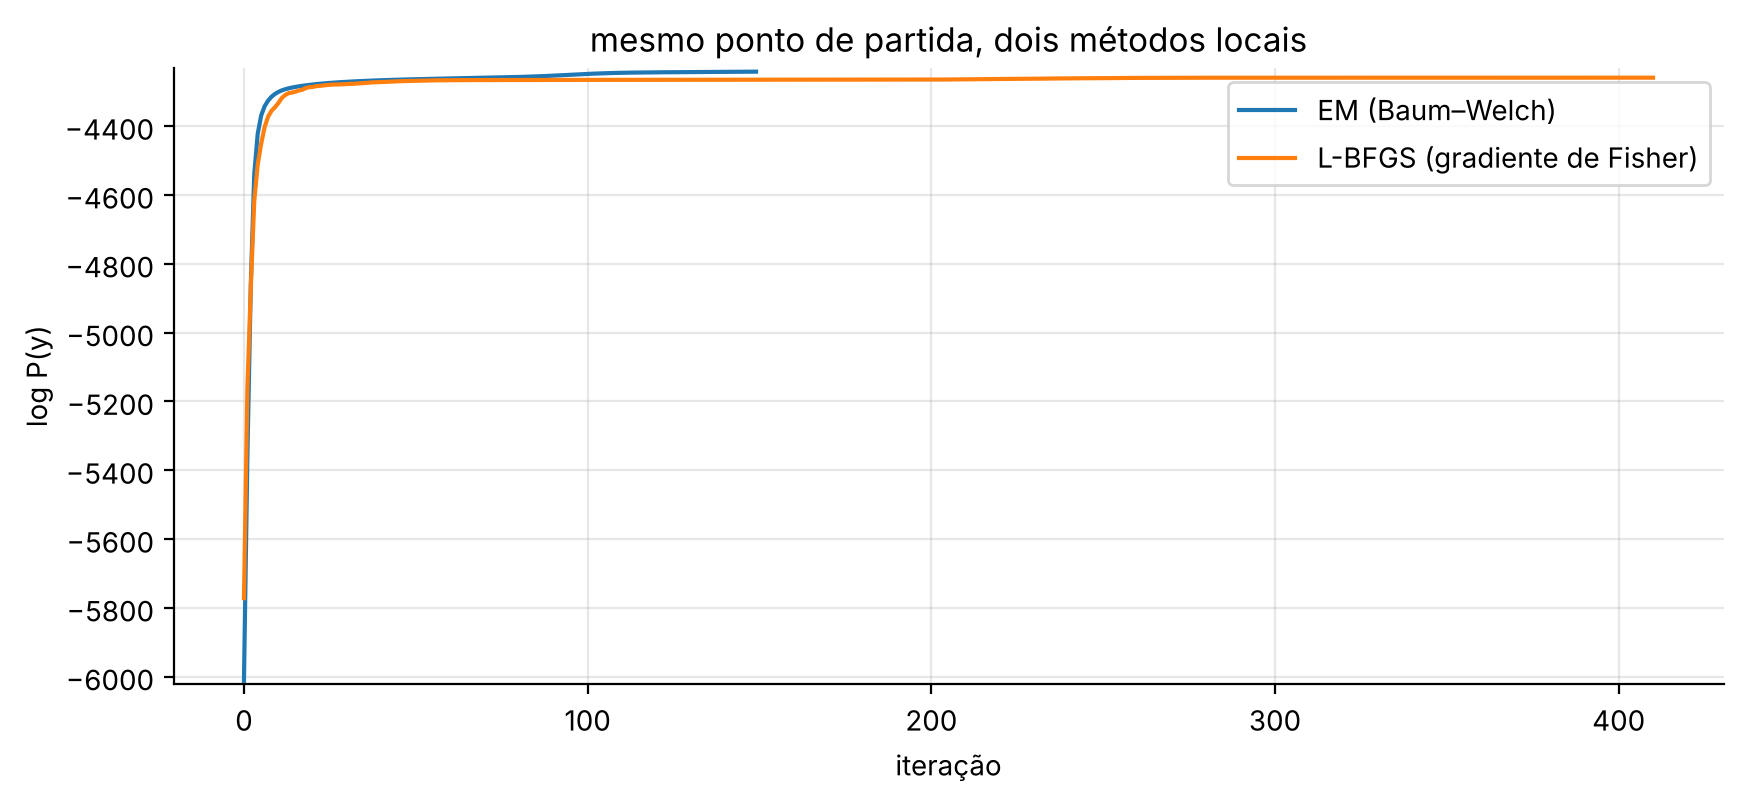

In [15]:
def softmax_linhas(Z): Z = Z - Z.max(-1, keepdims=True); E_ = np.exp(Z); return E_ / E_.sum(-1, keepdims=True)

def negll_e_grad(theta, y):
    a, b, p = theta[:n*n].reshape(n, n), theta[n*n:2*n*n].reshape(n, n), theta[2*n*n:]
    A, B, pi0 = softmax_linhas(a), softmax_linhas(b), softmax_linhas(p)
    gamma, Xi, ll, _ = e_passo_hmm(pi0, A, B, y)
    G = gamma.T @ onehot(y, n)                                   # emissões esperadas
    gA = Xi - A * Xi.sum(1, keepdims=True)
    gB = G - B * G.sum(1, keepdims=True)
    gp = gamma[0] - pi0
    return -ll, -np.concatenate([gA.ravel(), gB.ravel(), gp])

theta0 = np.concatenate([np.log(A_ini).ravel(), np.log(B_ini).ravel(), np.log(pi_ini)])
f0, g0 = negll_e_grad(theta0, y_h)
eps, j = 1e-6, 10
th_p = theta0.copy(); th_p[j] += eps; th_m = theta0.copy(); th_m[j] -= eps
num = (negll_e_grad(th_p, y_h)[0] - negll_e_grad(th_m, y_h)[0]) / (2*eps)
confere("gradiente pela identidade de Fisher = diferenças finitas", g0[j], num, tol=1e-4)

hist_lbfgs = []
res = minimize(negll_e_grad, theta0, args=(y_h,), jac=True, method="L-BFGS-B",
               callback=lambda th: hist_lbfgs.append(-negll_e_grad(th, y_h)[0]), options={"maxiter": 500})
A_lb, B_lb, pi_lb = softmax_linhas(res.x[:n*n].reshape(n, n)), softmax_linhas(res.x[n*n:2*n*n].reshape(n, n)), softmax_linhas(res.x[2*n*n:])
_, _, _, lls_volta = baum_welch(y_h, A_lb, B_lb, pi_lb, n_iter=30)        # EM partindo do ponto do L-BFGS
print(f"log-verossimilhança final:  EM {lls_em[-1]:.2f}  |  L-BFGS {-res.fun:.2f}  ({res.nit} iterações)")
print(f"30 iterações de EM a partir do ponto do L-BFGS: {lls_volta[0]:.2f} → {lls_volta[-1]:.2f}  ")
print(f"probabilidades < 10⁻³ na solução do EM: {(A_em < 1e-3).sum() + (B_em < 1e-3).sum()} de {2*n*n}")
plt.plot(lls_em, label="EM (Baum–Welch)"); plt.plot(hist_lbfgs, label="L-BFGS (gradiente de Fisher)")
plt.ylim(lls_em[0] - 10, max(lls_em[-1], -res.fun) + 10); plt.xlabel("iteração"); plt.ylabel("log P(y)"); plt.legend()
plt.title("mesmo ponto de partida, dois métodos locais"); plt.show()

**O que observar.** A conferência do gradiente passa, mas EM e L-BFGS **não precisam terminar no mesmo ponto**, e em geral não terminam. Isso ensina duas coisas.

- **A verossimilhança do HMM tem vários máximos locais.** EM e gradiente são métodos locais. Partindo do mesmo lugar, podem cair em bacias diferentes, e qualquer um dos dois pode acabar mais alto. O EM rodado a partir do ponto final do L-BFGS quase não melhora, o que indica que o L-BFGS já parou perto de um máximo local. Na prática, usam-se várias inicializações e fica-se com a melhor.
- **Fronteiras.** Muitas probabilidades do ótimo são praticamente zero; os saltos de duas posições, por exemplo, não existem. O EM chega a zero numa só divisão de contagens. Com *softmax*, um zero exige logits indo a $-\infty$, e o gradiente avança devagar nessa direção.

Num modelo com poucos parâmetros e longe das fronteiras, os dois métodos coincidem. É o que acontece com o Kalman em C4.

Com um modelo **estruturado**, de só dois parâmetros ($p_{\text{fica}}$ e $p_{\text{certo}}$), a superfície de verossimilhança pode ser desenhada. A figura correspondente para o Kalman aparece em C4.

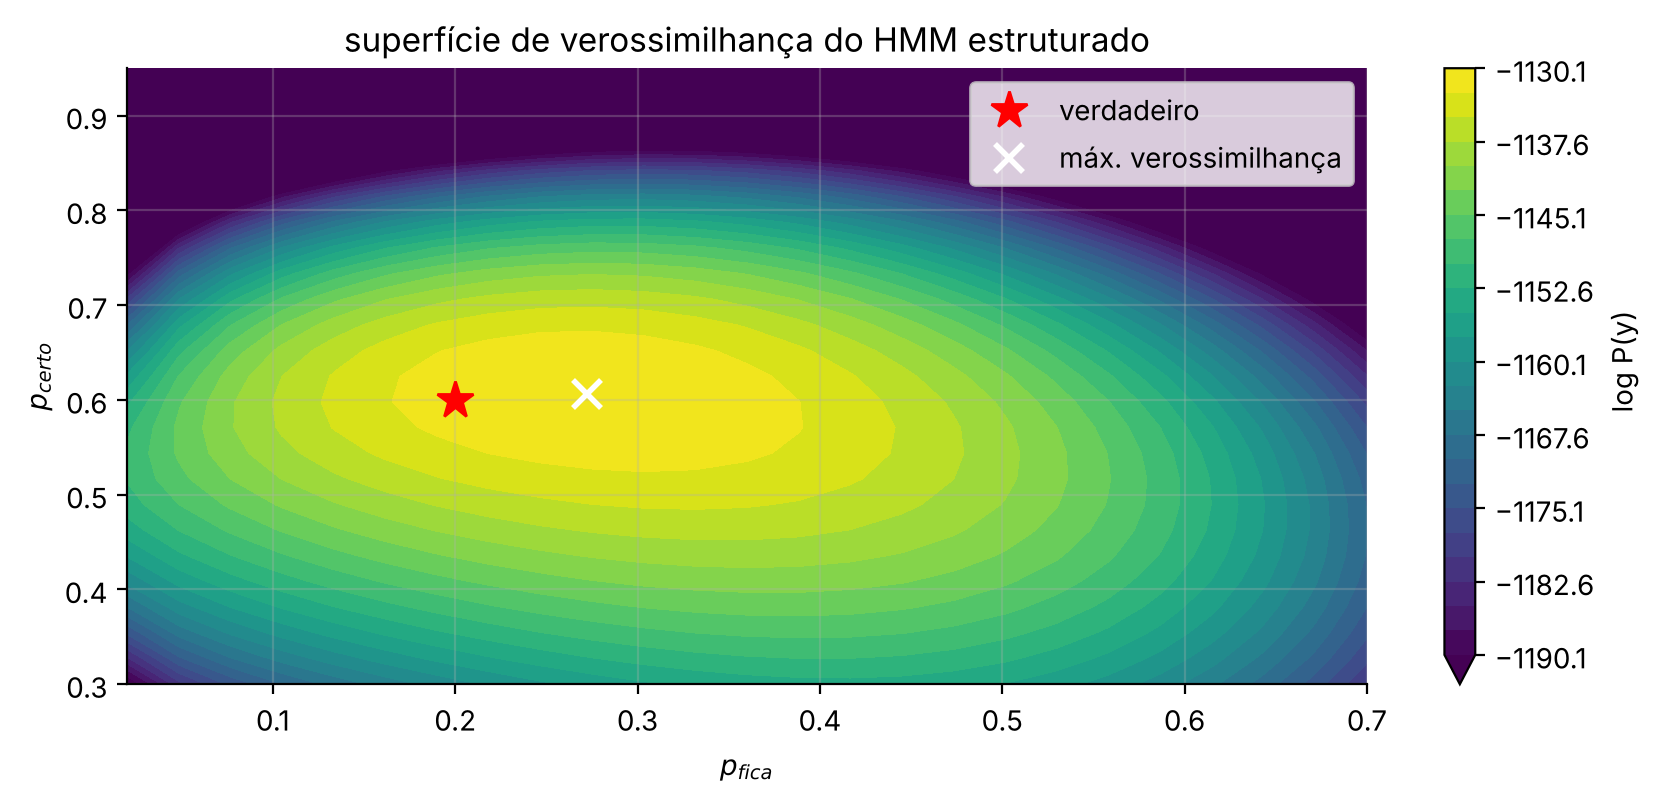

MV: p_fica = 0.272, p_certo = 0.606


In [16]:
y_curto = y_h[:800]
def ll2(pf, pc): return forward(pi_est, matriz_vizinhos(pf), matriz_vizinhos(pc), y_curto)[2]
pfs, pcs = np.linspace(0.02, 0.7, 25), np.linspace(0.3, 0.95, 25)
L = np.array([[ll2(pf, pc) for pf in pfs] for pc in pcs])
sig = lambda u: 1 / (1 + np.exp(-u))
r2 = minimize(lambda u: -ll2(sig(u[0]), sig(u[1])), [0.0, 0.0], method="Nelder-Mead")
pf_hat, pc_hat = sig(r2.x)
plt.contourf(pfs, pcs, L, levels=np.linspace(L.max() - 60, L.max(), 25), cmap="viridis", extend="min"); plt.colorbar(label="log P(y)")
plt.plot(0.2, 0.6, "r*", ms=14, label="verdadeiro"); plt.plot(pf_hat, pc_hat, "wx", ms=10, mew=2, label="máx. verossimilhança")
plt.xlabel(r"$p_{fica}$"); plt.ylabel(r"$p_{certo}$"); plt.legend(); plt.title("superfície de verossimilhança do HMM estruturado"); plt.show()
print(f"MV: p_fica = {pf_hat:.3f}, p_certo = {pc_hat:.3f}")

---
# Parte C — O encontro: o Filtro de Kalman

## C1. Kalman = *forward* com estado contínuo

Troque as 7 posições por uma reta contínua: o bêbado dá passos gaussianos, $x_t=Fx_{t-1}+w_t$ com $w_t\sim\mathcal N(0,Q)$, e o sensor mede a posição com ruído, $y_t=Hx_t+v_t$ com $v_t\sim\mathcal N(0,R)$. A recursão é **a mesma** do *forward*. Só que gaussianas continuam gaussianas, então basta propagar média e covariância:

Em cada linha, à esquerda o HMM (*forward*) e à direita o Kalman.

**Crença:** $\quad \alpha_t\ \text{(vetor de 7 números)} \quad\longleftrightarrow\quad (m_t,\,P_t)$

**Predição (média):** $\quad \alpha_t^-=\alpha_{t-1}A \quad\longleftrightarrow\quad m_t^-=F\,m_{t-1}$

**Predição (covariância), só no Kalman:** $\quad P_t^-=F P_{t-1}F^\top+Q$

**Normalização:** $\quad c_t=\sum_i\alpha_t^-(i)\,B_{i,y_t} \quad\longleftrightarrow\quad S_t=H P_t^-H^\top+R$

**Ganho, só no Kalman:** $\quad K_t=P_t^-H^\top S_t^{-1}$

**Atualização (média):** $\quad \alpha_t=\alpha_t^-\odot B_{:,y_t}\,/\,c_t \quad\longleftrightarrow\quad m_t=m_t^-+K_t\,(y_t-Hm_t^-)$

**Atualização (covariância), só no Kalman:** $\quad P_t=P_t^--K_tS_tK_t^\top$

**Verossimilhança:** $\quad \log p(y)=\sum_t\log c_t \quad\longleftrightarrow\quad \log p(y)=\sum_t\log\mathcal N(y_t;\,Hm_t^-,\,S_t)$

A atualização é a forma de ganho de A3 com o *prior* $(m^-,P^-)$. A verossimilhança é a **decomposição pelo erro de predição**: o produto das densidades das inovações.

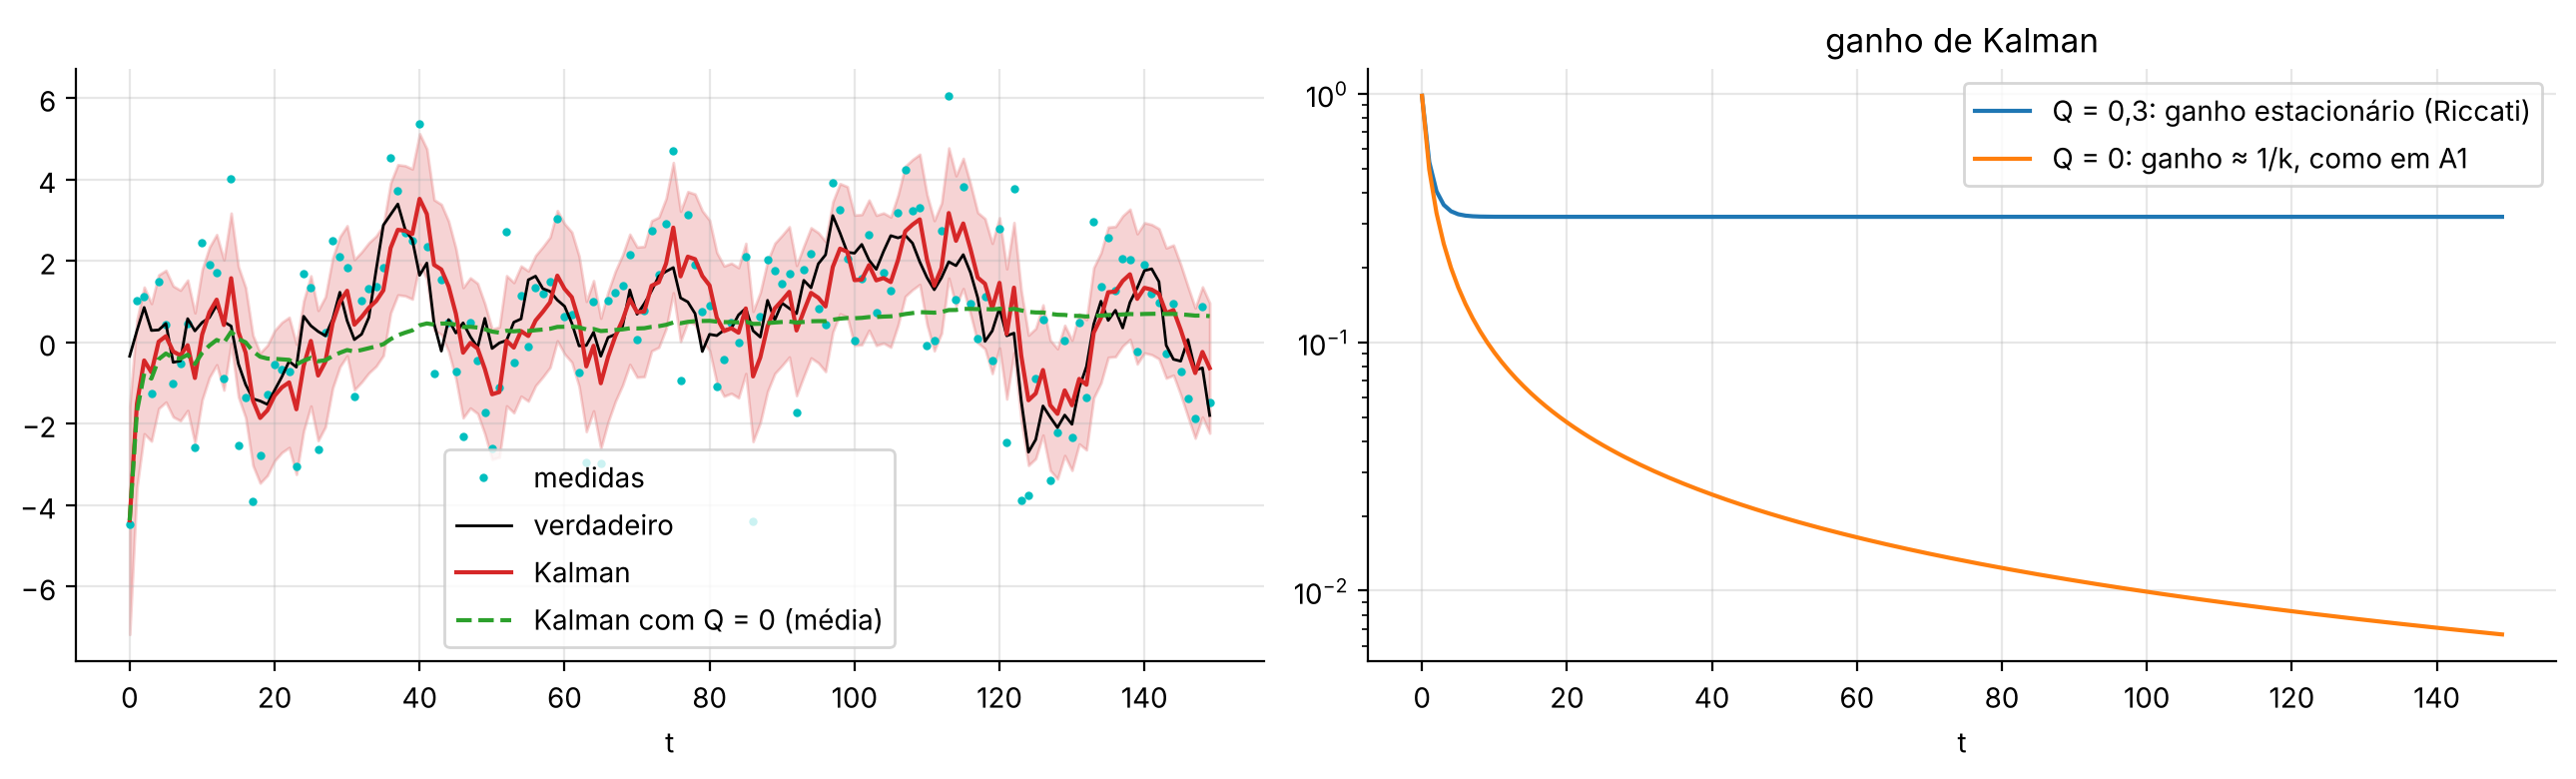

In [17]:
def kf_predicao(m, P, F, Q):
    return F @ m, F @ P @ F.T + Q

def kf_atualizacao(m, P, y, H, R):
    v = y - H @ m; S = H @ P @ H.T + R
    K = np.linalg.solve(S, H @ P).T                 # K = P Hᵀ S⁻¹
    m = m + K @ v; P = P - K @ S @ K.T; P = (P + P.T) / 2
    ll = -0.5 * (v @ np.linalg.solve(S, v) + np.linalg.slogdet(2*np.pi*S)[1])
    return m, P, ll, K

def kalman(Y, F, H, Q, R, m0, P0):
    T, nx = len(Y), len(m0)
    mp, Pp = np.empty((T, nx)), np.empty((T, nx, nx))
    mf, Pf, Ks = np.empty((T, nx)), np.empty((T, nx, nx)), []
    m, P, ll = m0, P0, 0.0
    for t in range(T):
        if t > 0: m, P = kf_predicao(m, P, F, Q)     # predição
        mp[t], Pp[t] = m, P
        m, P, l, K = kf_atualizacao(m, P, Y[t], H, R) # atualização
        mf[t], Pf[t] = m, P; ll += l; Ks.append(K)
    return dict(mp=mp, Pp=Pp, mf=mf, Pf=Pf, ll=ll, K=np.array(Ks))

# passeio do bêbado contínuo (modelo de nível local)
T1, q1, r1 = 150, 0.3, 2.0
x1 = np.cumsum(np.sqrt(q1) * rng.standard_normal(T1)); y1 = x1 + np.sqrt(r1) * rng.standard_normal(T1)
I1 = np.eye(1)
kf1 = kalman(y1[:, None], I1, I1, q1*I1, r1*I1, np.zeros(1), 100*I1)
kf0 = kalman(y1[:, None], I1, I1, 0*I1, r1*I1, np.zeros(1), 100*I1)     # Q = 0: volta à média de A1

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sd = np.sqrt(kf1["Pf"][:, 0, 0])
ax[0].plot(y1, "c.", ms=4, label="medidas"); ax[0].plot(x1, "k-", lw=1, label="verdadeiro")
ax[0].plot(kf1["mf"][:, 0], "C3", label="Kalman"); ax[0].fill_between(range(T1), kf1["mf"][:, 0]-2*sd, kf1["mf"][:, 0]+2*sd, color="C3", alpha=.2)
ax[0].plot(kf0["mf"][:, 0], "C2--", label="Kalman com Q = 0 (média)"); ax[0].legend(); ax[0].set_xlabel("t")
ax[1].plot(kf1["K"][:, 0, 0], label="Q = 0,3: ganho estacionário (Riccati)")
ax[1].plot(kf0["K"][:, 0, 0], label="Q = 0: ganho ≈ 1/k, como em A1")
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("ganho de Kalman"); ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

**O que observar.** O ruído de processo $Q$ impede o ganho de ir a zero: ele converge para um valor estacionário, solução da equação de Riccati. Com $Q=0$, o filtro reproduz a média de A1 e congela. É a versão "com modelo" do fator de esquecimento de A4.

## C2. Kalman com estado parado = RLS

Faça o "estado" ser o vetor de **parâmetros** de uma regressão: $F=I$, $Q=0$ e uma matriz de observação que muda com o tempo, $H_k=x_k^\top$ (a $k$-ésima linha de $\Phi$). O Kalman vira **exatamente** o RLS de A4. Conferimos com os 400 pontos da Função de Franke e as 65 funções de base: os pesos que o Kalman produz são os de A5.

Com $Q>0$, os parâmetros podem passear. É um RLS com esquecimento "com modelo", em que $Q$ diz **quanto** e **em que direção** cada parâmetro pode mudar. O fator $\lambda$ inflava todas as direções igualmente.

OK   Kalman (F=I, Q=0, H_k=φ_kᵀ) = RLS = ridge na Franke:  diferença máxima = 5.55e-12


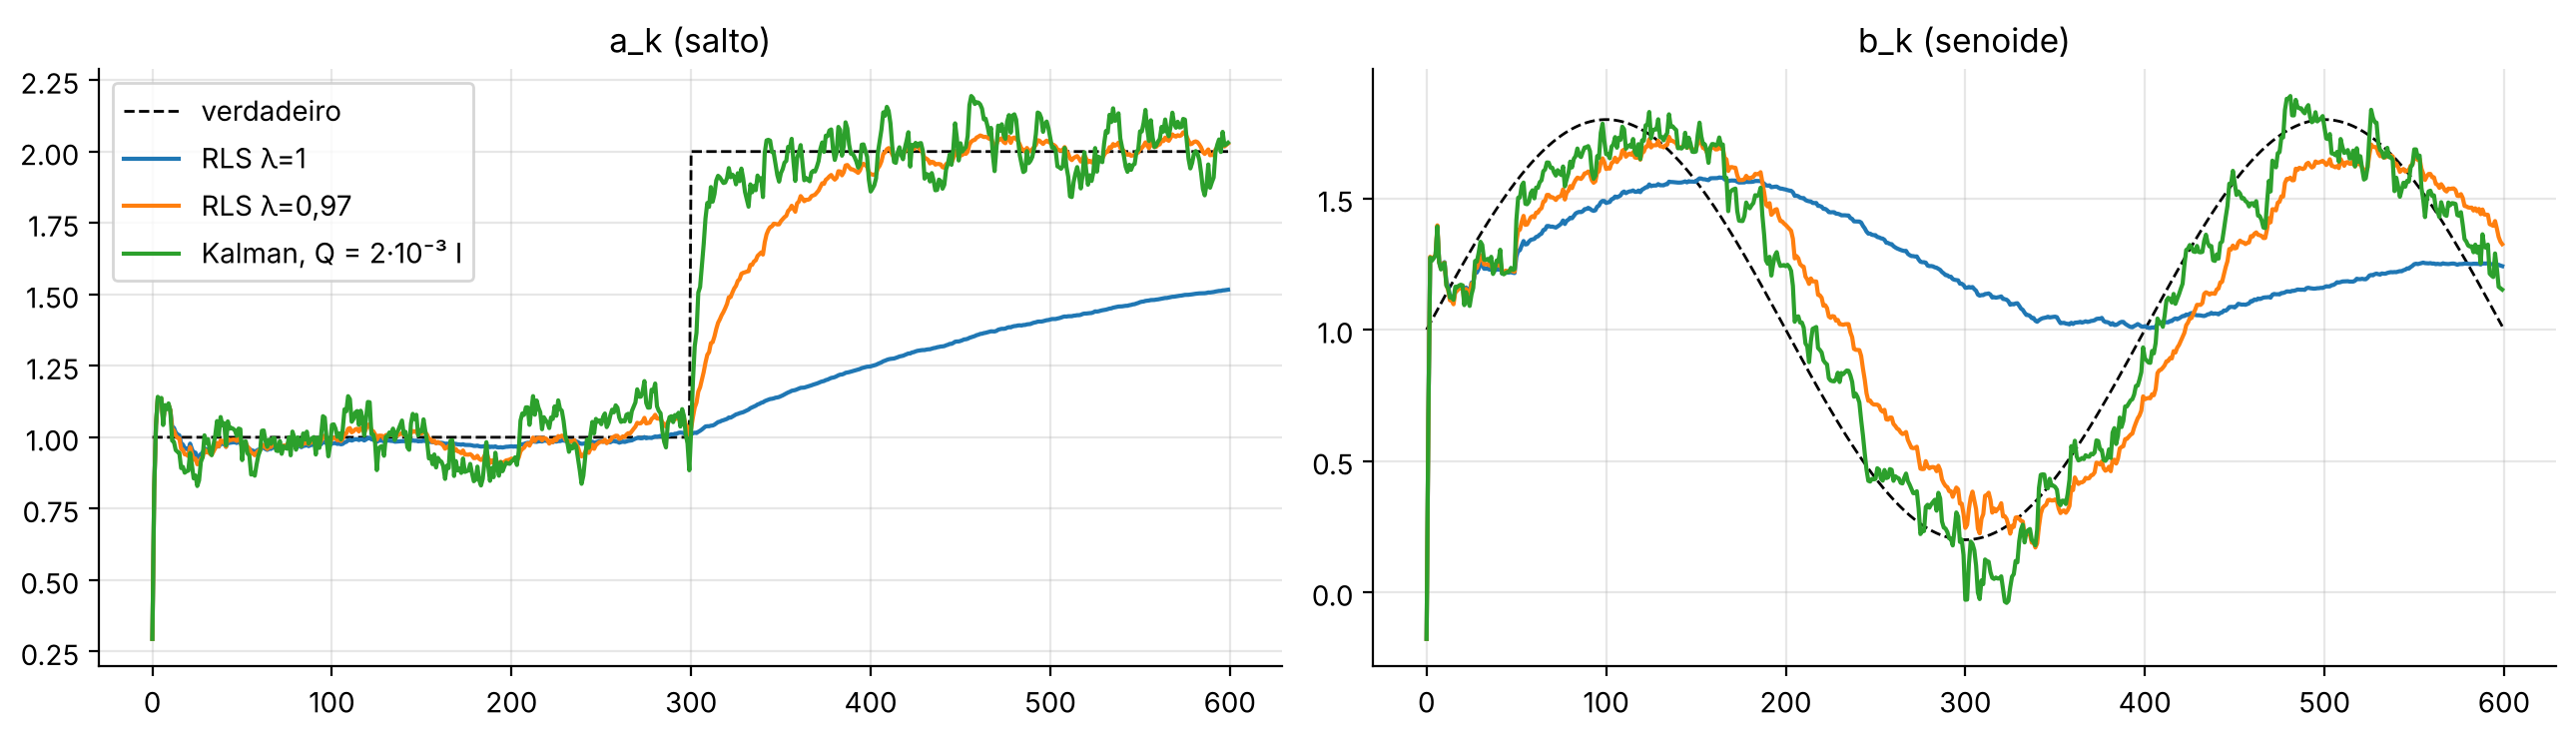

In [18]:
m, P = np.zeros(Dm), delta*np.eye(Dm)
for phi_k, y_k in zip(Phi, yf):
    m, P = kf_predicao(m, P, np.eye(Dm), np.zeros((Dm, Dm)))
    m, P, _, _ = kf_atualizacao(m, P, np.array([y_k]), phi_k[None, :], np.array([[sig_f**2]]))
confere("Kalman (F=I, Q=0, H_k=φ_kᵀ) = RLS = ridge na Franke", m, w_ridge, tol=1e-6)

# regressão com coeficientes variáveis: y_k = a_k + b_k u_k
Nv = 600; uv = rng.uniform(-1, 1, Nv); kk = np.arange(Nv)
a_v = np.where(kk < 300, 1.0, 2.0); b_v = 1 + 0.8*np.sin(2*np.pi*kk/400)
yv = a_v + b_v*uv + 0.3*rng.standard_normal(Nv); Xv = np.c_[np.ones(Nv), uv]
_, _, h_rls = rls(Xv, yv, 0.09, np.zeros(2), 10*np.eye(2), 1.0)
_, _, h_esq = rls(Xv, yv, 0.09, np.zeros(2), 10*np.eye(2), 0.97)
m, P, h_kf = np.zeros(2), 10*np.eye(2), []
Qv = np.diag([2e-3, 2e-3])
for xk, yk in zip(Xv, yv):
    m, P = kf_predicao(m, P, np.eye(2), Qv)
    m, P, _, _ = kf_atualizacao(m, P, np.array([yk]), xk[None, :], np.array([[0.09]])); h_kf.append(m)
h_kf = np.array(h_kf)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (a, verd, nome) in enumerate(zip(ax, [a_v, b_v], ["a_k (salto)", "b_k (senoide)"])):
    a.plot(verd, "k--", lw=1, label="verdadeiro"); a.plot(h_rls[:, i], label="RLS λ=1")
    a.plot(h_esq[:, i], label="RLS λ=0,97"); a.plot(h_kf[:, i], label="Kalman, Q = 2·10⁻³ I"); a.set_title(nome)
ax[0].legend(); plt.tight_layout(); plt.show()

## C3. Suavizador RTS = mínimos quadrados em lote da trajetória inteira

Agora o ponto central. A **trajetória MAP** de um modelo linear-gaussiano maximiza

$$\log p(x_{0:T},y_{0:T})=-\tfrac12\Big[\|x_0-m_0\|^2_{P_0^{-1}}+\sum_{t\ge1}\|x_t-Fx_{t-1}\|^2_{Q^{-1}}+\sum_t\|y_t-Hx_t\|^2_{R^{-1}}\Big]+\text{cte},$$

ou seja, minimiza **uma soma de quadrados**. Pelo truque de A3, cada termo vira um bloco de linhas "branqueadas" (multiplicadas por $L^\top$, onde $C^{-1}=LL^\top$) num único sistema $J\,\mathbf x\approx\mathbf b$, com $\mathbf x=(x_0,\dots,x_T)$ empilhado:

- o *prior* é o ridge de A3;
- a dinâmica é uma restrição suave entre estados vizinhos;
- as observações são as linhas de dados de A2.

**Afirmação.** A solução desse único `lstsq` coincide com as médias do suavizador de Rauch–Tung–Striebel. Os blocos diagonais de $(J^\top J)^{-1}$ coincidem com as covariâncias suavizadas. O filtro e o suavizador são só uma maneira **recursiva** e eficiente, $O(T)$, de resolver esse problema de mínimos quadrados com matriz bloco-tridiagonal. É o RLS de A4 aplicado à trajetória, e é o análogo exato do Viterbi de B4.

A função `gauss_newton_trajetoria` abaixo é escrita já para o caso **não linear**, $y_t=h(x_t)+v_t$. No caso linear, a primeira iteração de Gauss–Newton já é a solução exata. Ela será reaproveitada em C5.

Exemplo: modelo de **velocidade constante** com estado (posição, velocidade), em que só a posição é medida.

OK   RTS = mínimos quadrados em lote (médias):  diferença máxima = 2.18e-14
OK   RTS = blocos diagonais de (JᵀJ)⁻¹ (covariâncias):  diferença máxima = 1.58e-14
OK   último filtrado = último componente do MQ em lote:  diferença máxima = 7.77e-15
custo nas iterações de Gauss–Newton (caso linear): [7.4805468e+05 1.8527000e+02 1.8527000e+02] → converge em 1 passo


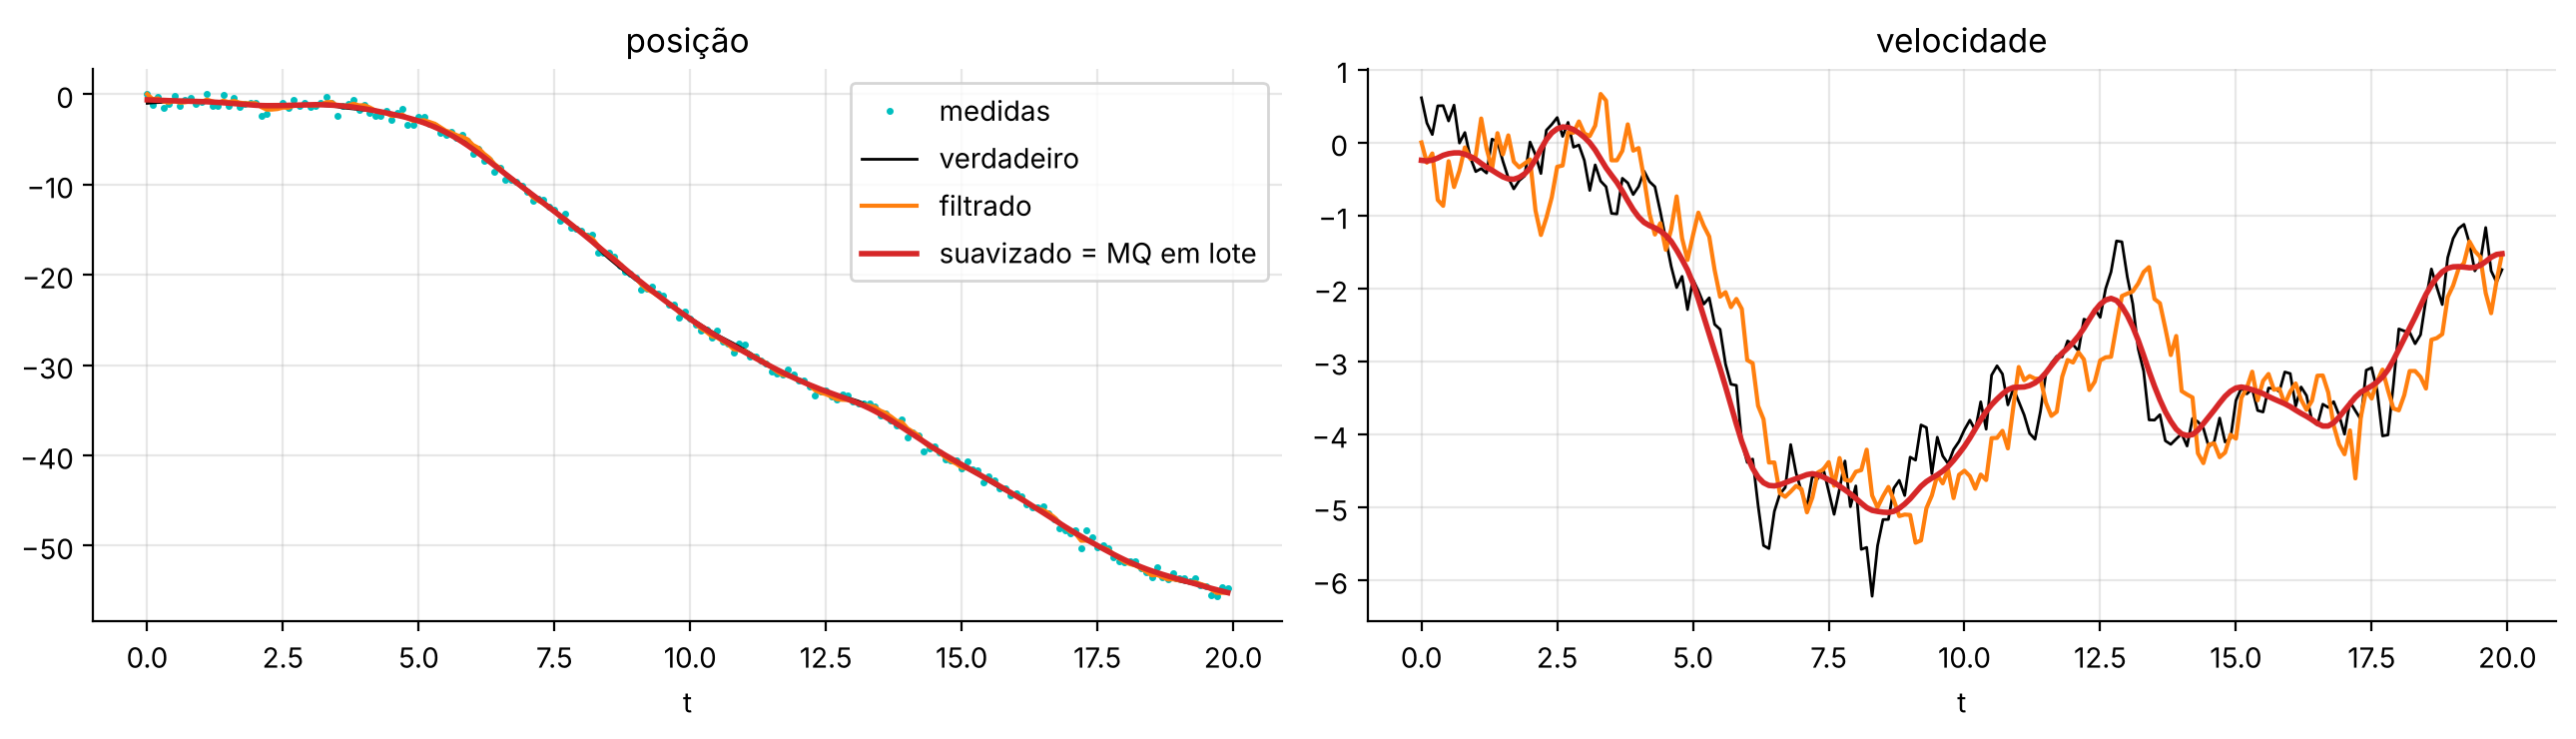

In [19]:
def rts(kf, F):
    mf, Pf, mp, Pp = kf["mf"], kf["Pf"], kf["mp"], kf["Pp"]
    T = len(mf); ms, Ps = mf.copy(), Pf.copy(); Pc = np.zeros_like(Pf)   # Pc[t] = Cov(x_t, x_{t-1} | y)
    for t in range(T - 2, -1, -1):
        J = Pf[t] @ F.T @ np.linalg.inv(Pp[t + 1])
        ms[t] = mf[t] + J @ (ms[t + 1] - mp[t + 1])
        Ps[t] = Pf[t] + J @ (Ps[t + 1] - Pp[t + 1]) @ J.T
        Pc[t + 1] = Ps[t + 1] @ J.T
    return ms, Ps, Pc

def branqueador(C):
    L = np.linalg.cholesky(np.linalg.inv(C)); return L.T      # ||Lᵀ r||² = rᵀ C⁻¹ r

def gauss_newton_trajetoria(Y, F, Q, R, m0, P0, h, Jh, X0, n_iter=30, angulo=None, tol=1e-10):
    T, nx = X0.shape; p = Y.shape[1]
    Wp, Wq, Wr = branqueador(P0), branqueador(Q), branqueador(R)
    def residuos(X):
        r = [Wp @ (X[0] - m0)] + [Wq @ (X[t] - F @ X[t - 1]) for t in range(1, T)]
        for t in range(T):
            e = Y[t] - h(X[t])
            if angulo is not None: e[angulo] = (e[angulo] + np.pi) % (2*np.pi) - np.pi
            r.append(Wr @ e)
        return np.concatenate(r)
    def jacobiano(X):
        J = np.zeros((nx + (T - 1)*nx + T*p, T*nx)); J[:nx, :nx] = Wp; lin = nx
        for t in range(1, T):
            J[lin:lin+nx, t*nx:(t+1)*nx] = Wq; J[lin:lin+nx, (t-1)*nx:t*nx] = -Wq @ F; lin += nx
        for t in range(T):
            J[lin:lin+p, t*nx:(t+1)*nx] = -Wr @ Jh(X[t]); lin += p
        return J
    X = X0.copy(); r = residuos(X); custos = [r @ r]
    for _ in range(n_iter):
        J = jacobiano(X)
        dx = np.linalg.lstsq(J, -r, rcond=None)[0].reshape(T, nx)    # passo de Gauss–Newton = um MQ linear
        passo = 1.0
        while True:                                                     # busca linear simples
            Xn = X + passo*dx; rn = residuos(Xn)
            if rn @ rn <= r @ r or passo < 1e-4: break
            passo /= 2
        X, r = Xn, rn; custos.append(r @ r)
        if abs(custos[-2] - custos[-1]) < tol * max(1, custos[-1]): break
    J = jacobiano(X)
    return X, np.array(custos), np.linalg.inv(J.T @ J)

dt, qa, rv, T3 = 0.1, 1.0, 0.5**2, 200
F3 = np.array([[1, dt], [0, 1]]); Q3 = qa*np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]])
H3 = np.array([[1.0, 0.0]]); R3 = np.array([[rv]]); m03, P03 = np.zeros(2), np.diag([1.0, 1.0])
x3 = np.zeros((T3, 2)); x3[0] = rng.multivariate_normal(m03, P03)
for t in range(1, T3): x3[t] = F3 @ x3[t - 1] + rng.multivariate_normal(np.zeros(2), Q3)
y3 = x3 @ H3.T + np.sqrt(rv)*rng.standard_normal((T3, 1))

kf3 = kalman(y3, F3, H3, Q3, R3, m03, P03); ms3, Ps3, Pc3 = rts(kf3, F3)
X_mq, custos3, Cov_mq = gauss_newton_trajetoria(y3, F3, Q3, R3, m03, P03, lambda x: H3 @ x, lambda x: H3, np.zeros((T3, 2)))
blocos = np.array([Cov_mq[2*t:2*t+2, 2*t:2*t+2] for t in range(T3)])
confere("RTS = mínimos quadrados em lote (médias)", ms3, X_mq, tol=1e-7)
confere("RTS = blocos diagonais de (JᵀJ)⁻¹ (covariâncias)", Ps3, blocos, tol=1e-7)
confere("último filtrado = último componente do MQ em lote", kf3["mf"][-1], X_mq[-1], tol=1e-7)
print("custo nas iterações de Gauss–Newton (caso linear):", custos3.round(2), "→ converge em 1 passo")

tt = np.arange(T3)*dt
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, nome in enumerate(["posição", "velocidade"]):
    if i == 0: ax[i].plot(tt, y3[:, 0], "c.", ms=3, label="medidas")
    ax[i].plot(tt, x3[:, i], "k-", lw=1, label="verdadeiro"); ax[i].plot(tt, kf3["mf"][:, i], "C1", label="filtrado")
    ax[i].plot(tt, X_mq[:, i], "C3", lw=2, label="suavizado = MQ em lote"); ax[i].set_title(nome); ax[i].set_xlabel("t")
ax[0].legend(); plt.tight_layout(); plt.show()

## C4. Os parâmetros: EM (Shumway–Stoffer) e otimização direta

Assim como em B5–B6, há duas vias para estimar $F$, $Q$ e $R$. Usamos um AR(1) observado com ruído: $x_t=\phi x_{t-1}+w_t$, $y_t=x_t+v_t$, com parâmetros $(\phi,q,r)$.

**EM.** O passo E é o Kalman mais o RTS, que fornecem $\mathbb E[x_t]$, $\mathrm{Cov}[x_t]$ e a covariância cruzada $\mathrm{Cov}[x_t,x_{t-1}]=P_{t|T}J_{t-1}^\top$. O passo M é **a mesma regressão de B5**:

$$\hat F^\top=\texttt{mq\_momentos}\Big(\underbrace{\textstyle\sum\mathbb E[x_{t-1}x_{t-1}^\top]}_{S_{00}},\;\underbrace{\textstyle\sum\mathbb E[x_{t-1}x_t^\top]}_{S_{01}}\Big),\qquad \hat Q=\frac{S_{11}-\hat FS_{01}}{T-1},\qquad \hat R=\frac1T\sum_t\big[(y_t-Hm_{t|T})(\cdot)^\top+HP_{t|T}H^\top\big].$$

No HMM, $\mathbb E[e\,e^\top]=\mathrm{diag}(\gamma)$ e $\mathbb E[e_{t-1}e_t^\top]=\xi$. No LDS, $\mathbb E[xx^\top]=P_{t|T}+m_{t|T}m_{t|T}^\top$. **As covariâncias são parte dos momentos.** Se forem esquecidas, usando só as médias suavizadas como faz o passo M de Benhamou, as estimativas ficam viciadas. A célula roda as duas versões.

**Otimização direta.** A verossimilhança do Kalman (soma das log-densidades das inovações, C1) é entregue ao L-BFGS, exatamente como em B6.

In [20]:
T4, phi_v, q_v, r_v = 500, 0.9, 0.5, 1.0
x4 = np.zeros(T4)
for t in range(1, T4): x4[t] = phi_v*x4[t - 1] + np.sqrt(q_v)*rng.standard_normal()
y4 = (x4 + np.sqrt(r_v)*rng.standard_normal(T4))[:, None]
m04, P04 = np.zeros(1), 5*np.eye(1); H4 = np.eye(1)

def em_lds(Y, F, Q, R, n_iter=300, com_covariancias=True):
    T = len(Y); hist = []
    for _ in range(n_iter):
        kf = kalman(Y, F, H4, Q, R, m04, P04); ms, Ps, Pc = rts(kf, F)    # passo E
        hist.append((kf["ll"], F[0, 0], Q[0, 0], R[0, 0]))
        if not com_covariancias: Ps, Pc = 0*Ps, 0*Pc
        Exx = Ps + np.einsum("ti,tj->tij", ms, ms)
        Exx_lag = Pc[1:] + np.einsum("ti,tj->tij", ms[1:], ms[:-1])       # E[x_t x_{t-1}ᵀ]
        S00, S11, S01 = Exx[:-1].sum(0), Exx[1:].sum(0), Exx_lag.sum(0).T
        F = mq_momentos(S00, S01).T                                         # passo M = MQ (a mesma linha de B5)
        Q = (S11 - F @ S01 - S01.T @ F.T + F @ S00 @ F.T) / (T - 1)
        res = Y - ms @ H4.T
        R = (res.T @ res + np.einsum("ij,tjk,lk->il", H4, Ps, H4)) / T
    return F, Q, R, np.array(hist)

F_ini, Q_ini, R_ini = 0.5*np.eye(1), 2*np.eye(1), 0.3*np.eye(1)
F_em, Q_em, R_em, h_em = em_lds(y4, F_ini, Q_ini, R_ini)
F_mm, Q_mm, R_mm, h_mm = em_lds(y4, F_ini, Q_ini, R_ini, com_covariancias=False)
assert np.all(np.diff(h_em[:, 0]) > -1e-7); print("EM do LDS monótono: OK")

def negll_lds(u):
    return -kalman(y4, np.tanh(u[0])*np.eye(1), H4, np.exp(u[1])*np.eye(1), np.exp(u[2])*np.eye(1), m04, P04)["ll"]
r4 = minimize(negll_lds, [np.arctanh(0.5), np.log(2.0), np.log(0.3)], method="L-BFGS-B")
phi_o, q_o, r_o = np.tanh(r4.x[0]), np.exp(r4.x[1]), np.exp(r4.x[2])

print(f"{'':28s}{'φ':>8s}{'q':>8s}{'r':>8s}{'log-veross.':>14s}")
print(f"{'verdadeiro':28s}{phi_v:8.3f}{q_v:8.3f}{r_v:8.3f}")
print(f"{'EM (com covariâncias)':28s}{F_em[0,0]:8.3f}{Q_em[0,0]:8.3f}{R_em[0,0]:8.3f}{h_em[-1,0]:14.2f}")
print(f"{'otimização direta (L-BFGS)':28s}{phi_o:8.3f}{q_o:8.3f}{r_o:8.3f}{-r4.fun:14.2f}")
print(f"{'EM só com médias (errado)':28s}{F_mm[0,0]:8.3f}{Q_mm[0,0]:8.3f}{R_mm[0,0]:8.3f}{h_mm[-1,0]:14.2f}")
confere("EM e otimização direta chegam ao mesmo máximo (log-veross.)", h_em[-1, 0], -r4.fun, tol=1e-2)

EM do LDS monótono: OK


                                   φ       q       r   log-veross.
verdadeiro                     0.900   0.500   1.000
EM (com covariâncias)          0.864   0.482   1.021       -862.53
otimização direta (L-BFGS)     0.864   0.482   1.021       -862.53
EM só com médias (errado)      0.554   2.028   0.000       -886.22
OK   EM e otimização direta chegam ao mesmo máximo (log-veross.):  diferença máxima = 2.97e-09


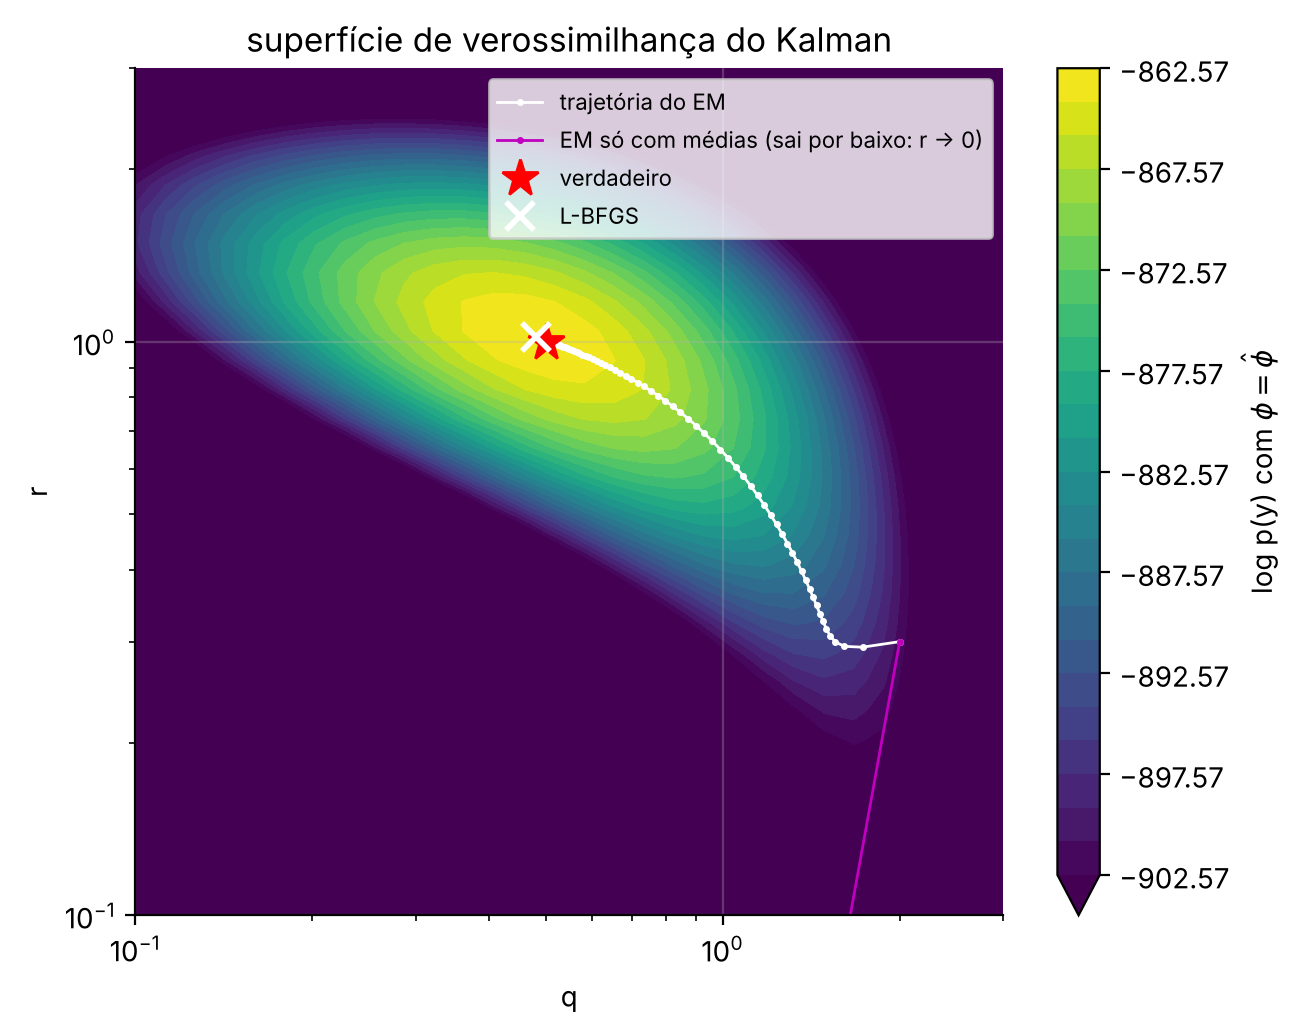

In [21]:
lq, lr = np.linspace(np.log(0.1), np.log(3), 30), np.linspace(np.log(0.1), np.log(3), 30)
LL = np.array([[-negll_lds([np.arctanh(phi_o), a, b]) for a in lq] for b in lr])
plt.figure(figsize=(7, 5.5))
plt.contourf(np.exp(lq), np.exp(lr), LL, levels=np.linspace(LL.max() - 40, LL.max(), 25), cmap="viridis", extend="min")
plt.colorbar(label=r"log p(y) com $\phi=\hat\phi$")
plt.plot(h_em[:, 2], h_em[:, 3], "w.-", ms=3, lw=1, label="trajetória do EM")
plt.plot(h_mm[:, 2], h_mm[:, 3], "m.-", ms=3, lw=1, label="EM só com médias (sai por baixo: r → 0)")
plt.plot(q_v, r_v, "r*", ms=14, label="verdadeiro"); plt.plot(q_o, r_o, "wx", ms=10, mew=2, label="L-BFGS")
plt.xscale("log"); plt.yscale("log"); plt.xlim(0.1, 3); plt.ylim(0.1, 3)
from matplotlib.ticker import NullFormatter; plt.gca().xaxis.set_minor_formatter(NullFormatter()); plt.gca().yaxis.set_minor_formatter(NullFormatter())
plt.xlabel("q"); plt.ylabel("r"); plt.legend(fontsize=8, loc="upper right")
plt.title("superfície de verossimilhança do Kalman"); plt.show()

**O que observar.** O EM correto e o L-BFGS chegam ao mesmo ponto, como no HMM. O EM "só com médias" foge para uma solução que atribui quase tudo ao processo e quase nada ao sensor. Isso acontece porque as médias suavizadas são mais lisas que a trajetória verdadeira: ignorar $P_{t|T}$ subestima a variabilidade do estado e deforma toda a estimação.

## C5. Caso não linear: EKF, Kalman iterado = Gauss–Newton, suavização em lote

Um radar na origem mede **distância e azimute** de um alvo com velocidade (quase) constante no plano:

$$h(x)=\begin{bmatrix}\sqrt{p_x^2+p_y^2}\\ \operatorname{atan2}(p_y,p_x)\end{bmatrix}.$$

A atualização ótima de um passo ainda é a minimização do χ² de Thacker & Lacey, agora com $h$ não linear:

$$\chi^2(x)=(x-m^-)^\top P^{-1}(x-m^-)+(z-h(x))^\top R^{-1}(z-h(x)).$$

- **EKF**: lineariza $h$ **uma vez**, em $m^-$, e aplica a atualização linear. Isso equivale a **um único passo de Gauss–Newton** a partir de $m^-$.
- **IEKF (Kalman iterado)**: relineariza no novo ponto e repete,
$$x_{i+1}=m^-+K_i\big[z-h(x_i)-H_i(m^--x_i)\big],\qquad K_i=P^-H_i^\top(H_iP^-H_i^\top+R)^{-1},\quad H_i=\partial h/\partial x|_{x_i}.$$
Essas iterações são **idênticas às de Gauss–Newton** sobre o χ² (Bell & Cathey, 1993). Cada iteração é um problema de **mínimos quadrados linear**, o mesmo de A3.
- **Suavizador por Gauss–Newton em lote**: aplica-se Gauss–Newton à trajetória inteira, usando a mesma `gauss_newton_trajetoria` de C3. No caso linear ela convergia em um passo; agora precisa de várias iterações. É a abordagem moderna de SLAM e grafos de fatores.

Primeiro conferimos, num único passo de atualização, que as iterações do IEKF coincidem com as de Gauss–Newton.

In [22]:
def h_radar(x): return np.array([np.hypot(x[0], x[1]), np.arctan2(x[1], x[0])])
def Jh_radar(x):
    r2 = x[0]**2 + x[1]**2; r = np.sqrt(r2)
    return np.array([[x[0]/r, x[1]/r, 0, 0], [-x[1]/r2, x[0]/r2, 0, 0]])
def ajusta_angulo(e): e = e.copy(); e[1] = (e[1] + np.pi) % (2*np.pi) - np.pi; return e

def iekf_atualizacao(m, P, z, R, n_iter):
    x, hist = m.copy(), [m.copy()]
    for _ in range(n_iter):
        H = Jh_radar(x); S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
        x = m + K @ (ajusta_angulo(z - h_radar(x)) - H @ (m - x)); hist.append(x.copy())
    H = Jh_radar(x); S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
    return x, (np.eye(len(m)) - K @ H) @ P, np.array(hist)

def gn_um_passo(m, P, z, R, n_iter):
    x, hist, Pi, Ri = m.copy(), [m.copy()], np.linalg.inv(P), np.linalg.inv(R)
    for _ in range(n_iter):
        H = Jh_radar(x)
        g = H.T @ Ri @ ajusta_angulo(z - h_radar(x)) - Pi @ (x - m)
        x = x + np.linalg.solve(Pi + H.T @ Ri @ H, g); hist.append(x.copy())
    return np.array(hist)

m_t, P_t = np.array([3.0, 2.0, 0.5, 0.0]), np.diag([4.0, 4.0, 1.0, 1.0])
z_t, R_t = np.array([2.0, 1.2]), np.diag([0.1**2, 0.02**2])
_, _, h_iekf = iekf_atualizacao(m_t, P_t, z_t, R_t, 6); h_gn = gn_um_passo(m_t, P_t, z_t, R_t, 6)
confere("iterações do IEKF = iterações de Gauss–Newton no χ²", h_iekf, h_gn, tol=1e-9)
m_ekf, _, _, _ = kf_atualizacao(m_t, P_t, z_t - h_radar(m_t) + Jh_radar(m_t) @ m_t, Jh_radar(m_t), R_t)
confere("EKF = primeira iteração de Gauss–Newton", m_ekf, h_gn[1], tol=1e-9)
print("posição ao longo das iterações (x, y):\n", h_gn[:, :2].round(4))

OK   iterações do IEKF = iterações de Gauss–Newton no χ²:  diferença máxima = 1.33e-15
OK   EKF = primeira iteração de Gauss–Newton:  diferença máxima = 8.88e-16
posição ao longo das iterações (x, y):
 [[3.     2.    ]
 [0.445  2.9452]
 [0.9511 1.8801]
 [0.7215 1.8796]
 [0.7264 1.866 ]
 [0.7263 1.866 ]
 [0.7263 1.866 ]]


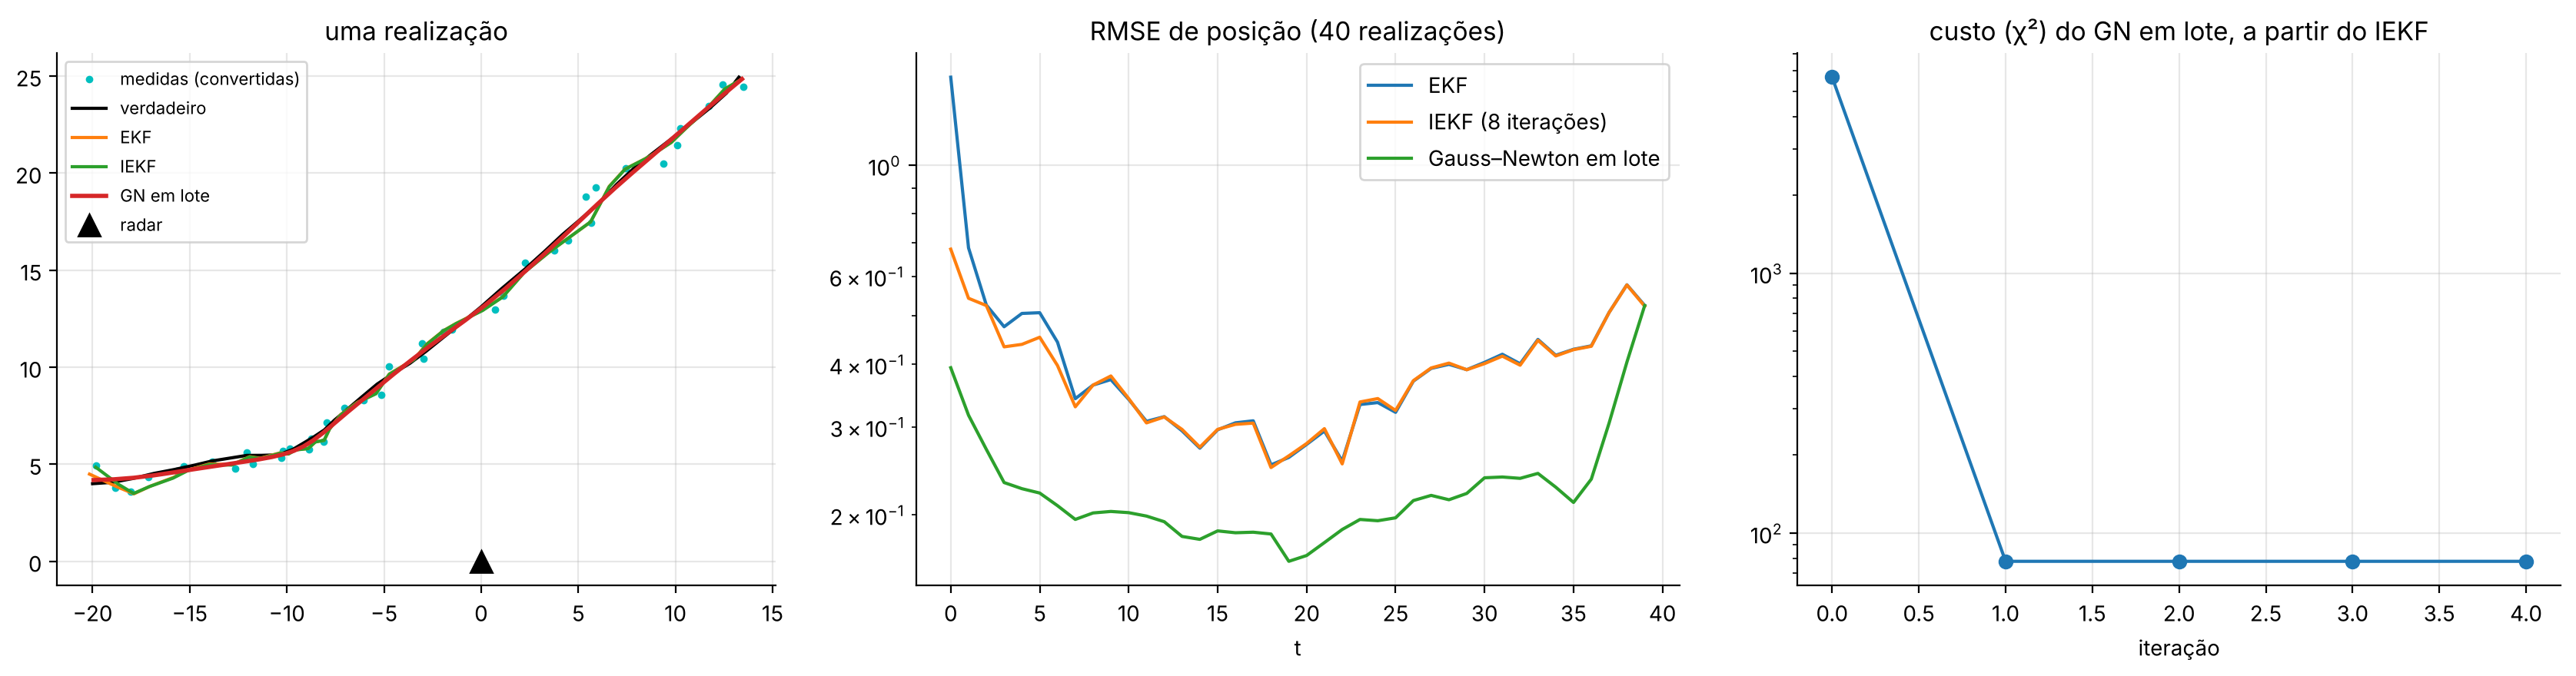

EKF                    RMSE médio de posição: 0.460
IEKF (8 iterações)     RMSE médio de posição: 0.397
Gauss–Newton em lote   RMSE médio de posição: 0.240


In [23]:
dt5, T5, q5 = 1.0, 40, 0.01
F5 = np.kron(np.array([[1, dt5], [0, 1]]), np.eye(2))     # estado (px, py, vx, vy)
Q5 = q5*np.kron(np.array([[dt5**3/3, dt5**2/2], [dt5**2/2, dt5]]), np.eye(2))
R5 = np.diag([0.3**2, 0.03**2]); P05 = np.diag([16.0, 16.0, 0.25, 0.25]); m05_verd = np.array([-20.0, 4.0, 1.0, 0.0])

def filtro_radar(Z, m0, n_iter):
    m, P, out = m0, P05, []
    for t in range(len(Z)):
        if t > 0: m, P = kf_predicao(m, P, F5, Q5)
        m, P, _ = iekf_atualizacao(m, P, Z[t], R5, n_iter); out.append(m)
    return np.array(out)

erros = {"EKF": [], "IEKF (8 iterações)": [], "Gauss–Newton em lote": []}
for rep in range(40):
    x5 = np.zeros((T5, 4)); x5[0] = m05_verd
    for t in range(1, T5): x5[t] = F5 @ x5[t - 1] + rng.multivariate_normal(np.zeros(4), Q5)
    Z5 = np.array([h_radar(x) for x in x5]) + rng.multivariate_normal(np.zeros(2), R5, T5)
    m05 = m05_verd + rng.multivariate_normal(np.zeros(4), P05)        # prior coerente com P0
    X_ekf, X_iekf = filtro_radar(Z5, m05, 1), filtro_radar(Z5, m05, 8)
    X_gn, custos5, _ = gauss_newton_trajetoria(Z5, F5, Q5, R5, m05, P05, h_radar, Jh_radar, X_iekf, angulo=1)
    for nome, X in zip(erros, [X_ekf, X_iekf, X_gn]):
        erros[nome].append(np.hypot(*(X[:, :2] - x5[:, :2]).T))
    if rep == 0: guarda = (x5, Z5, X_ekf, X_iekf, X_gn, custos5)

x5, Z5, X_ekf, X_iekf, X_gn, custos5 = guarda
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
zxy = np.c_[Z5[:, 0]*np.cos(Z5[:, 1]), Z5[:, 0]*np.sin(Z5[:, 1])]
ax[0].plot(*zxy.T, "c.", ms=5, label="medidas (convertidas)"); ax[0].plot(*x5[:, :2].T, "k-", label="verdadeiro")
ax[0].plot(*X_ekf[:, :2].T, "C1", label="EKF"); ax[0].plot(*X_iekf[:, :2].T, "C2", label="IEKF")
ax[0].plot(*X_gn[:, :2].T, "C3", lw=2, label="GN em lote"); ax[0].plot(0, 0, "k^", ms=10, label="radar")
ax[0].set_aspect("equal"); ax[0].legend(fontsize=8); ax[0].set_title("uma realização")
for nome, e in erros.items(): ax[1].plot(np.sqrt(np.mean(np.array(e)**2, 0)), label=nome)
ax[1].set_yscale("log"); ax[1].set_xlabel("t"); ax[1].set_title("RMSE de posição (40 realizações)"); ax[1].legend()
ax[2].semilogy(custos5, "o-"); ax[2].set_xlabel("iteração"); ax[2].set_title("custo (χ²) do GN em lote, a partir do IEKF")
plt.tight_layout(); plt.show()
for nome, e in erros.items(): print(f"{nome:22s} RMSE médio de posição: {np.sqrt(np.mean(np.array(e)**2)):.3f}")

**O que observar.**

- O EKF sofre no começo, quando a incerteza do *prior* é grande frente à curvatura de $h$, e de novo quando o alvo passa perto do radar, onde o azimute muda depressa. Linearizar uma vez, num ponto ruim, é dar um único passo de Gauss–Newton e parar.
- O IEKF continua iterando até o mínimo do χ² de cada passo.
- O suavizador em lote resolve o problema de mínimos quadrados não linear da trajetória inteira. Ele usa também os dados **futuros**, por isso não é comparável com os filtros em tempo real: é a referência *offline*, o análogo contínuo do Viterbi.

## C5b. Quando o EKF erra com certeza: o exemplo de Bell & Cathey

Bell & Cathey (1993) provam a equivalência entre o Kalman iterado e Gauss–Newton que conferimos em C5. Eles fazem isso com o mesmo truque de A3 e C3: a estimativa anterior $\hat x$ entra como mais uma observação,

$$Z=\begin{bmatrix}z\\ \hat x\end{bmatrix},\qquad g(\xi)=\begin{bmatrix}h(\xi)\\ \xi\end{bmatrix},\qquad \min_\xi\;(Z-g(\xi))^\top\,\mathrm{blkdiag}(R,P)^{-1}\,(Z-g(\xi)).$$

*Atenção à notação:* o $Q$ do artigo é essa matriz $\mathrm{blkdiag}(R,P)$, **não** o ruído de processo.

O mais valioso do artigo é um exemplo em que o EKF **erra e afirma ter certeza**.

- **Geometria.** Duas estações em $A=(-1,0)$ e $B=(+1,0)$ medem metade do quadrado da distância ao alvo: $h(\xi)=\tfrac12\big[(\xi_1+1)^2+\xi_2^2,\;(\xi_1-1)^2+\xi_2^2\big]$.
- **Dados.** O alvo está em $x=(0,1)$, e a medida é exata: $z=h(x)$. A estimativa anterior é $\hat x=\beta x$, com $\beta=2$ e $P=I$. O sensor tem $R=p\,I$.
- **EKF.** Quando $p\to0$, a média vai para $\frac{1+\beta^2}{2\beta}\,x=(0;\;1{,}25)$, enquanto a covariância vai a **zero**. A estimativa fica enviesada e o filtro "certo" dela.
- **Kalman iterado.** Quando $p\to0$, as iterações viram $\rho_{i+1}=\frac{1+\rho_i^2}{2\rho_i}$, que é o **método de Newton para $\sqrt1$**, e convergem para $x$.
- **Máxima verossimilhança.** Para $p$ qualquer, o estimador é $\rho^\star x$, onde $\rho^\star$ é a maior raiz da cúbica $\rho^3+(p-1)\rho-p\beta=0$.

O mecanismo é geral. Quando uma medida exata determina o estado por completo, o EKF resolve **um** passo de Newton da equação $h(\xi)=z$ e para ali. Ao mesmo tempo, a fórmula de covariância, que só enxerga o jacobiano, declara que o estado ficou perfeitamente determinado.

In [24]:
A_est, B_est = np.array([-1.0, 0.0]), np.array([1.0, 0.0])
def h_bi(x): return 0.5*np.array([np.sum((x - A_est)**2), np.sum((x - B_est)**2)])
def Jh_bi(x): return np.vstack([x - A_est, x - B_est])

x_bi, beta = np.array([0.0, 1.0]), 2.0
z_bi, xh_bi, P_bi = h_bi(x_bi), beta*np.array([0.0, 1.0]), np.eye(2)

def atualizacao_iterada(m, P, z, R, h, Jh, n_iter):
    # Kalman iterado na forma de Bell & Cathey: cada iteração parte da PREDIÇÃO m
    x, hist = m.copy(), [m.copy()]
    for _ in range(n_iter):
        H = Jh(x); K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
        x = m + K @ (z - h(x) - H @ (m - x)); hist.append(x.copy())
    H = Jh(x); K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
    return x, (np.eye(len(m)) - K @ H) @ P, np.array(hist)

ps = np.logspace(-8, 0, 33); res_bi = []
for p in ps:
    R = p*np.eye(2)
    xe, Pe, _ = atualizacao_iterada(xh_bi, P_bi, z_bi, R, h_bi, Jh_bi, 1)     # EKF = 1 iteração
    xi, Pi, _ = atualizacao_iterada(xh_bi, P_bi, z_bi, R, h_bi, Jh_bi, 60)    # IEKF
    raiz = np.max(np.real(np.roots([1, 0, p - 1, -p*beta])))
    res_bi.append((np.linalg.norm(xe - x_bi), np.sqrt(np.trace(Pe)), np.linalg.norm(xi - x_bi), np.sqrt(np.trace(Pi)),
                   xi[1], raiz, xe[1]))
res_bi = np.array(res_bi)

confere("EKF → (1+β²)/(2β)·x quando p → 0", res_bi[0, 6], (1 + beta**2)/(2*beta), tol=1e-6)
confere("IEKF = máx. verossimilhança (maior raiz da cúbica), para todo p", res_bi[:, 4], res_bi[:, 5], tol=1e-9)
_, _, h_newton = atualizacao_iterada(xh_bi, P_bi, z_bi, 1e-12*np.eye(2), h_bi, Jh_bi, 6)
rho = [beta]
for _ in range(6): rho.append((1 + rho[-1]**2) / (2*rho[-1]))
confere("iterações do IEKF (p → 0) = método de Newton para √1", h_newton[:, 1], rho, tol=1e-6)
print(f"\np = 1e-8:  EKF  erro {res_bi[0,0]:.3f}, desvio-padrão declarado {res_bi[0,1]:.1e}"
      f"  → erro/desvio = {res_bi[0,0]/res_bi[0,1]:.0e}")
print(f"           IEKF erro {res_bi[0,2]:.1e}, desvio-padrão declarado {res_bi[0,3]:.1e}")

OK   EKF → (1+β²)/(2β)·x quando p → 0:  diferença máxima = 9.37e-10
OK   IEKF = máx. verossimilhança (maior raiz da cúbica), para todo p:  diferença máxima = 8.88e-16
OK   iterações do IEKF (p → 0) = método de Newton para √1:  diferença máxima = 5.00e-13

p = 1e-8:  EKF  erro 0.250, desvio-padrão declarado 9.1e-05  → erro/desvio = 3e+03
           IEKF erro 5.0e-09, desvio-padrão declarado 1.0e-04


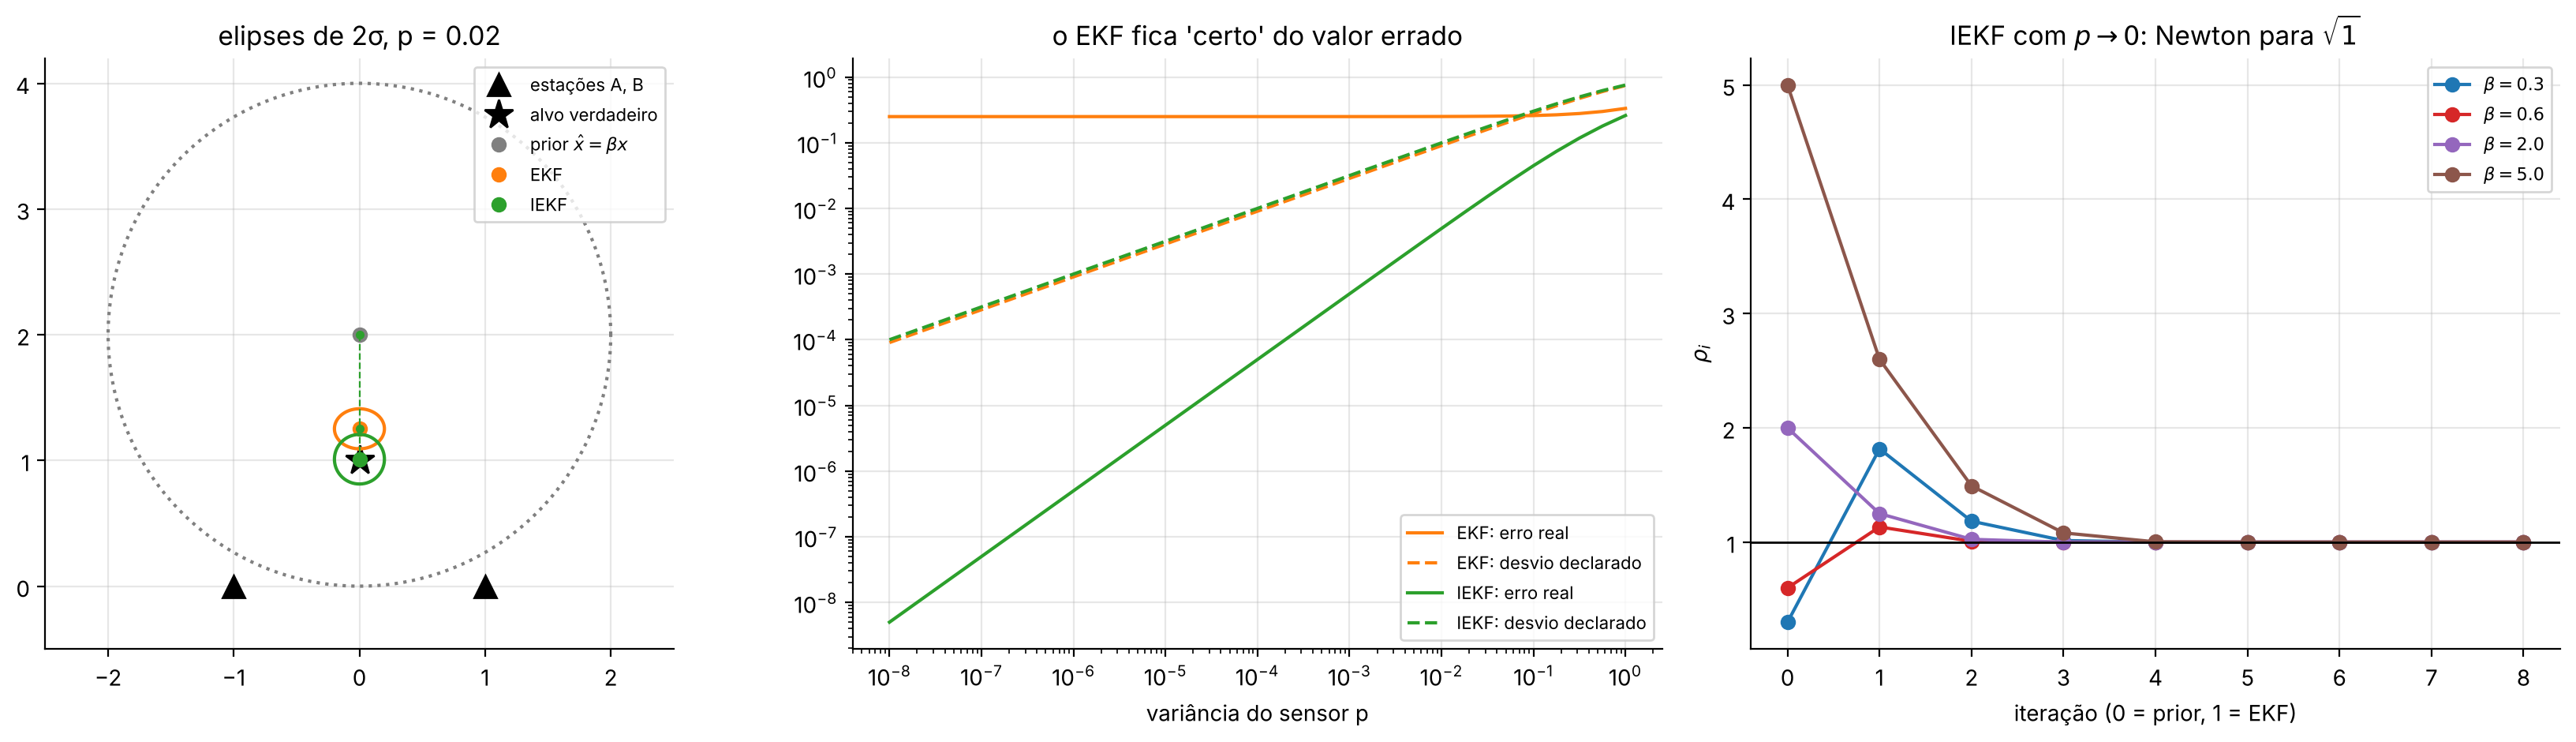

In [25]:
def elipse(ax, m, C, cor, k=2, **kw):
    w, V = np.linalg.eigh(C); t = np.linspace(0, 2*np.pi, 200)
    pts = m[:, None] + k * V @ (np.sqrt(np.maximum(w, 0))[:, None] * np.array([np.cos(t), np.sin(t)]))
    ax.plot(*pts, color=cor, **kw)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
p_fig = 0.02; R = p_fig*np.eye(2)
xe, Pe, _ = atualizacao_iterada(xh_bi, P_bi, z_bi, R, h_bi, Jh_bi, 1)
xi, Pi, hi = atualizacao_iterada(xh_bi, P_bi, z_bi, R, h_bi, Jh_bi, 60)
ax[0].plot(*np.c_[A_est, B_est], "k^", ms=10, label="estações A, B")
ax[0].plot(*x_bi, "k*", ms=14, label="alvo verdadeiro")
ax[0].plot(*xh_bi, "o", color="gray", label=r"prior $\hat x=\beta x$"); elipse(ax[0], xh_bi, P_bi, "gray", ls=":")
ax[0].plot(*xe, "o", color="C1", label="EKF"); elipse(ax[0], xe, Pe, "C1")
ax[0].plot(*xi, "o", color="C2", label="IEKF"); elipse(ax[0], xi, Pi, "C2")
ax[0].plot(*hi[:6].T, "C2.--", lw=.8)
ax[0].set_aspect("equal"); ax[0].set_xlim(-2.5, 2.5); ax[0].set_ylim(-0.5, 4.2); ax[0].legend(fontsize=8, loc="upper right")
ax[0].set_title(f"elipses de 2σ, p = {p_fig}")

ax[1].loglog(ps, res_bi[:, 0], "C1-", label="EKF: erro real")
ax[1].loglog(ps, res_bi[:, 1], "C1--", label="EKF: desvio declarado")
ax[1].loglog(ps, res_bi[:, 2], "C2-", label="IEKF: erro real")
ax[1].loglog(ps, res_bi[:, 3], "C2--", label="IEKF: desvio declarado")
ax[1].set_xlabel("variância do sensor p"); ax[1].legend(fontsize=8); ax[1].set_title("o EKF fica 'certo' do valor errado")

for b, cor in zip([0.3, 0.6, 2.0, 5.0], ["C0", "C3", "C4", "C5"]):
    xb = b*np.array([0.0, 1.0])
    _, _, hb = atualizacao_iterada(xb, P_bi, z_bi, 1e-12*np.eye(2), h_bi, Jh_bi, 8)
    ax[2].plot(hb[:, 1], "o-", color=cor, label=fr"$\beta={b}$")
ax[2].axhline(1, color="k", lw=1); ax[2].set_xlabel("iteração (0 = prior, 1 = EKF)"); ax[2].set_ylabel(r"$\rho_i$")
ax[2].set_title(r"IEKF com $p\to0$: Newton para $\sqrt{1}$"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**O que observar.**

- **Painel do meio.** A razão entre o erro real e o desvio declarado do EKF cresce sem limite quando $p\to0$. Os dois filtros declaram praticamente o **mesmo** desvio (as linhas tracejadas se sobrepõem): a diferença está só no ponto em que cada um para. O erro do IEKF fica sempre abaixo do desvio declarado, e o do EKF estaciona em 0,25. Um teste de consistência (NEES) acusaria o EKF, mas o filtro, sozinho, não tem como saber.
- **Painel da direita.** A primeira iteração (o EKF) é **um passo de Newton**. Com $\beta=2$ ele vai de 2 para 1,25, longe da resposta. As iterações seguintes completam o trabalho com convergência quadrática.

Isso explica a recomendação de Thacker & Lacey de substituir o EKF por uma minimização iterativa do χ², e mostra por que um $P_0$ pequeno demais é perigoso: ele declara confiança que o filtro não tem.

### Exercício de leitura crítica: a fórmula do IEKF em Im (2024)

As notas de Im (*Notes on Kalman Filter*, arXiv:2406.06427) apresentam o IEKF assim, nas eqs. (71)–(72):

$$\delta\hat x_{j}=K_{j}\big(z-h(\hat x_{j})-H(\hat x^- -\hat x_{j})\big),\qquad \hat x_{j+1}=\hat x_{j}+\delta\hat x_{j}.$$

A célula abaixo implementa a fórmula **exatamente como está escrita** e a compara com a de Bell & Cathey (usada em `atualizacao_iterada`). O teste usa dois casos: um linear trivial e o exemplo biestático. **Antes de ler a resposta, descubra o que está errado.**

linear (z = 2, R = 1)    componente 0:  correta [0. 1. 1. 1. 1. 1. 1. 1. 1.]
                                       Im [0. 1. 2. 3. 4. 5. 6. 7. 8.]
biestático (p = 0,02)    componente 1:  correta [2.    1.252 1.032 1.01  1.01  1.01  1.01  1.01  1.01 ]
                                       Im [  2.      1.252   0.283   0.2     0.681  -0.225  -3.845  -7.895 -13.905]


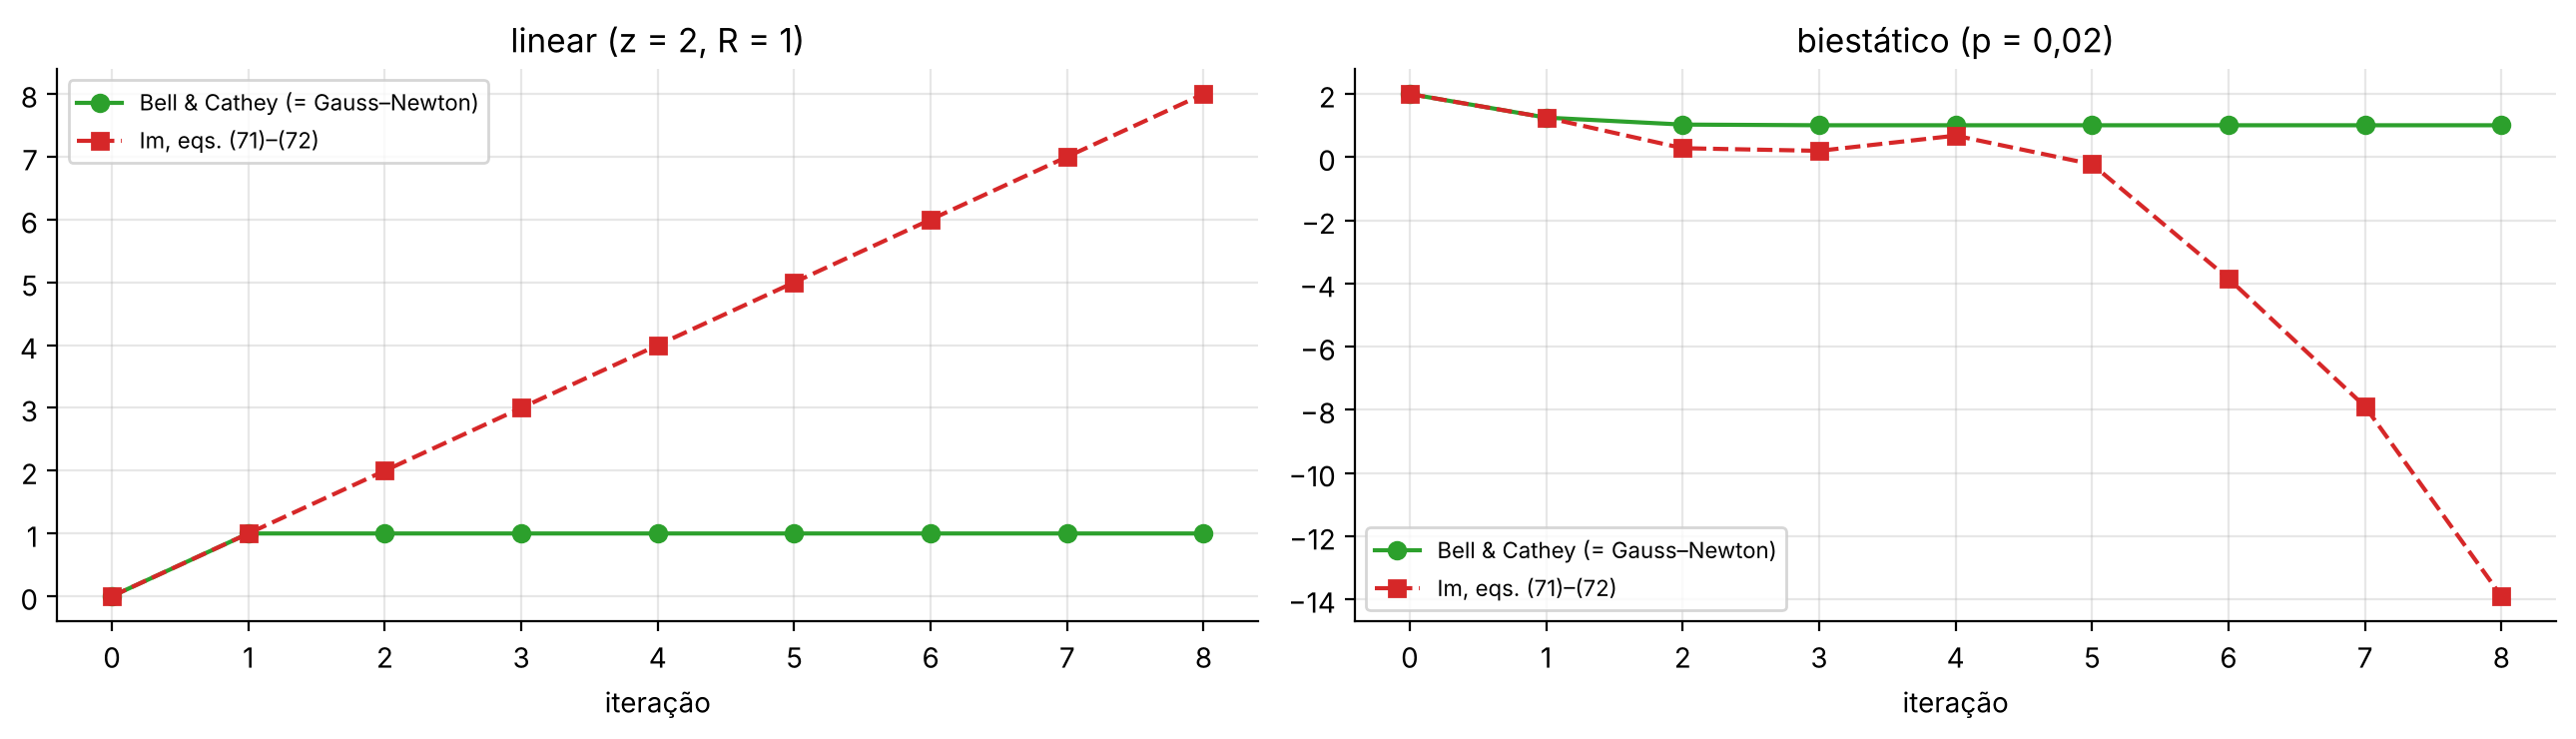

OK   as duas fórmulas coincidem na 1ª iteração (= EKF):  diferença máxima = 0.00e+00


In [26]:
def iekf_como_em_im(m, P, z, R, h, Jh, n_iter):
    # Eqs. (71)-(72) de Im (2024), transcritas literalmente
    x, hist = m.copy(), [m.copy()]
    for _ in range(n_iter):
        H = Jh(x); K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
        delta = K @ (z - h(x) - H @ (m - x))
        x = x + delta; hist.append(x.copy())
    return np.array(hist)

# caso linear: mede-se só a primeira coordenada, z = 2
Hl = np.array([[1.0, 0.0]])
casos = {
    "linear (z = 2, R = 1)": (np.zeros(2), np.eye(2), np.array([2.0]), np.eye(1), lambda x: Hl @ x, lambda x: Hl),
    "biestático (p = 0,02)": (xh_bi, P_bi, z_bi, 0.02*np.eye(2), h_bi, Jh_bi),
}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (nome, (m, P, z, R, h, Jh)) in zip(ax, casos.items()):
    errado = iekf_como_em_im(m, P, z, R, h, Jh, 8)
    certo = atualizacao_iterada(m, P, z, R, h, Jh, 8)[2]
    k = 0 if "linear" in nome else 1
    a.plot(certo[:, k], "C2o-", label="Bell & Cathey (= Gauss–Newton)")
    a.plot(errado[:, k], "C3s--", label="Im, eqs. (71)–(72)")
    a.set_title(nome); a.set_xlabel("iteração"); a.legend(fontsize=8)
    print(f"{nome:24s} componente {k}:  correta {np.round(certo[:, k], 3)}\n{'':24s}               Im {np.round(errado[:, k], 3)}")
plt.tight_layout(); plt.show()
confere("as duas fórmulas coincidem na 1ª iteração (= EKF)",
        iekf_como_em_im(xh_bi, P_bi, z_bi, 0.02*np.eye(2), h_bi, Jh_bi, 1)[1],
        atualizacao_iterada(xh_bi, P_bi, z_bi, 0.02*np.eye(2), h_bi, Jh_bi, 1)[2][1], tol=1e-12)

<details>
<summary><b>Resposta (leia depois de tentar)</b></summary>

O incremento $K_j\big(z-h(\hat x_j)-H_j(\hat x^- -\hat x_j)\big)$ é o deslocamento **a partir da predição** $\hat x^-$, e não a partir do iterado atual. A fórmula correta é

$$\hat x_{j+1}=\hat x^- + K_j\big(z-h(\hat x_j)-H_j(\hat x^- -\hat x_j)\big),$$

que é a de Bell & Cathey e a que o próprio Im deduz mais adiante, na eq. (158). As duas versões coincidem na primeira iteração ($\hat x_0=\hat x^-$, o EKF). Isso explica por que o erro passa despercebido em quem só testa um passo.

No caso linear, o incremento é sempre o mesmo, $K(z-H\hat x^-)$, e a versão de Im o soma a cada iteração: a estimativa anda 1, 2, 3, … e diverge. Há um segundo deslize na mesma linha: o jacobiano que multiplica $(\hat x^- -\hat x_j)$ deve ser o do iterado, $H_{t,j}$, e não $H_t$.

**Lição.** Uma derivação correta em um lugar do texto não garante uma transcrição correta em outro. Confira cada fórmula num caso em que a resposta é conhecida (aqui, o caso linear, em que o IEKF tem de parar em uma iteração), exatamente como fizemos com `confere` ao longo do notebook.
</details>

## C6. Quadro-síntese

| Conceito | Trilha A (contínua, estática) | Trilha B (discreta, HMM) | Kalman (contínuo, dinâmico) |
|---|---|---|---|
| crença | $(\hat\theta,P)$ | $\alpha_t$ | $(m_t,P_t)$ |
| predição | — (ou $P/\lambda$) | $\alpha_{t-1}A$ | $Fm$, $FPF^\top+Q$ |
| atualização | ganho do RLS | $\odot B_{:,y}$ e normalização | ganho de Kalman |
| verossimilhança | resíduos | $\prod c_t$ | densidades das inovações |
| suavização | — | *forward–backward* | RTS = **MQ em lote** |
| trajetória ótima | — | Viterbi (programação dinâmica) | média suavizada = **MQ em lote** |
| parâmetros com estado observado | MQ (equação normal) | MQ *one-hot* = contagens | MQ de $x_t$ sobre $x_{t-1}$ |
| parâmetros com estado oculto | — | EM: **MQ com momentos esperados** $(\gamma,\xi)$ | EM: **MQ com momentos esperados** $(m,P,P_{t,t-1})$ |
| otimização direta | — | L-BFGS com gradiente de Fisher | L-BFGS na verossimilhança das inovações |
| não linear | Gauss–Newton (MQ iterado) | — | EKF = 1 passo de GN; IEKF = GN; suavizador = GN em lote |
| perigo do passo único | — | — | EKF pode convergir ao valor errado com $P\to0$ (C5b) |

Duas frases para levar:

1. **Kalman = RLS + dinâmica**, e **Kalman = HMM com estado gaussiano**. Os dois caminhos chegam ao mesmo lugar porque a recursão bayesiana predição–atualização é uma só.
2. **Quase tudo é mínimos quadrados**: a estimação com estado observado, o passo M do EM (com momentos esperados), a suavização linear (um `lstsq` só) e cada iteração do caso não linear (Gauss–Newton). O limite está nas perdas não quadráticas (L1, Huber, *outliers*), que são o tema natural do próximo notebook.

## Exercícios

1. **(A1)** Mostre que, com $P_0=\infty$, as equações do Kalman escalar com $Q=0$ produzem $K_k=1/k$. O que acontece com $P_0$ finito? Qual é o *prior* implícito?
2. **(A4)** Deduza a atualização de $P$ do RLS a partir da fórmula de Sherman–Morrison aplicada a $P_k^{-1}=P_{k-1}^{-1}+x_kx_k^\top/\sigma^2$.
3. **(A5)** Mude a largura `s_rbf` e o número de centros. Como muda o mapa de incerteza? Relacione com a escolha do *kernel* no processo gaussiano.
4. **(B1)** Prove que, para regressores *one-hot*, $(X^\top X)^{-1}X^\top Y$ tem linhas que somam 1 e entradas não negativas sempre que as linhas de $Y$ também forem *one-hot*.
5. **(B4)** Construa uma matriz $A$ e uma sequência $y$ em que o argmax das marginais produza uma transição impossível. Por que no caso gaussiano isso nunca acontece?
6. **(B5/C4)** Implemente o EM do modelo de velocidade constante de C3 estimando o parâmetro $q_a$ de $Q$ com a estrutura fixa. Dica: o passo M continua sendo um problema de mínimos quadrados, agora com restrição de estrutura.
7. **(C4)** Leia o passo M do artigo de Benhamou (*Kalman Filter Demystified*). Identifique os termos de covariância que faltam e explique o vício observado na figura.
8. **(C5)** Contamine 5% das medidas de distância com *outliers* grandes. Substitua o quadrado no resíduo de observação pela perda de Huber, resolvida por **mínimos quadrados reponderados iterativamente** dentro do mesmo laço de Gauss–Newton. Compare com o EKF.

## Referências

- G. Welch, G. Bishop. *An Introduction to the Kalman Filter*. SIGGRAPH Course 8, 2001.
- N. A. Thacker, A. J. Lacey. *Tutorial: The Likelihood Interpretation of the Kalman Filter*. Tina Memo 1996-002.
- S. Roweis, Z. Ghahramani. A Unifying Review of Linear Gaussian Models. *Neural Computation* 11(2), 1999.
- F. Stulp, O. Sigaud. Many regression algorithms, one unified model: A review. *Neural Networks* 69, 2015.
- E. Benhamou. *Kalman Filter Demystified*. HAL, 2019 (leitura crítica).
- R. H. Shumway, D. S. Stoffer. An approach to time series smoothing and forecasting using the EM algorithm. *J. Time Series Analysis* 3(4), 1982.
- B. M. Bell, F. W. Cathey. The iterated Kalman filter update as a Gauss–Newton method. *IEEE Trans. Automatic Control* 38(2), 1993.
- G. E. Im. *Notes on Kalman Filter (KF, EKF, ESKF, IEKF, IESKF)*. arXiv:2406.06427, 2024 (leitura crítica; útil para ESKF/IESKF em variedades).
- R. J. Elliott, L. Aggoun, J. B. Moore. *Hidden Markov Models: Estimation and Control*. Springer, 1995.
- L. R. Rabiner. A tutorial on hidden Markov models and selected applications in speech recognition. *Proc. IEEE* 77(2), 1989.